In [9]:
import pandas as pd
import numpy as np
import re
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment.util import *
from nltk import tokenize
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk.data
from textblob import TextBlob
import statsmodels.api as sm
from loess.loess_1d import loess_1d
import matplotlib.pyplot as plt
import scienceplots

# Apply matplotlib style
plt.style.use(['science', 'notebook'])

In [10]:
data_sentiment = pd.read_csv("tm_cov_V2.csv")
data_sentiment.insert(0, 'ID', range(1, 1 + len(data_sentiment)))
def clean_text(text): # Clean the 'Full Text' column and create a new 'Clean_Text' column
    if pd.isna(text):
        return ""
    text = text.lower()
    text = re.sub(r'[\-+%$]*\d+[\-+%$]*', '', text)       # Remove numbers with attached symbols like -2050
    text = re.sub(r'\n\n', ' ', text)                     # Replace double newlines with space
    text = re.sub(r'\n', ' ', text)                       # Replace single newlines with space
    text = re.sub(r'\\', '', text)                        # Remove backslashes
    text = re.sub(r'•|●', '', text)                       # Remove bullet points
    text = re.sub(r'\u2028', '', text)                    # Remove Unicode line separator
    text = re.sub(r'\\"|“|”|‘|’|\'\'', '', text)           # Remove quotation marks and curly quotes
    text = re.sub(r'\([^)]*\)', '', text)                 # Remove anything inside parentheses
    text = re.sub(r'\.\s*%', '.', text) 
    text = re.sub(r'\s*%', '', text)
    text = re.sub(r'\s+', ' ', text)                      # Squeeze multiple spaces into one
    return text.strip()

In [11]:
data_sentiment['Clean_Text'] = data_sentiment['Full Text'].apply(clean_text)
data_sentiment = data_sentiment[['ID', 'Title', 'Month', 'Year', 'Clean_Text']]

In [12]:
nltk.download('punkt')
tokenizer = nltk.data.load('tokenizers/punkt/english.pickle')
def split_sentences(text):
    if pd.isna(text) or text.strip() == "":
        return []
    newText = '\n-----\n'.join(tokenizer.tokenize(text))
    sentences = newText.split('\n-----\n')
    return sentences

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/nurbek.bektursynicloud.com/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [13]:
data_sentiment['Sentences'] = data_sentiment['Clean_Text'].apply(split_sentences)
data_sentiment

,ID,Title,Month,Year,Clean_Text,Sentences
0,1,Address of the President of the Republic of Ka...,October,1997,"prosperity, security and ever growing welfare ...","[prosperity, security and ever growing welfare..."
1,2,Address of the President of the Republic of Ka...,September,1998,on the situation in the country and major dire...,[on the situation in the country and major dir...
2,3,Address of the President of the Republic of Ka...,September,1999,stability and security countries in the new ce...,[stability and security countries in the new c...
3,4,Address of the President of the Republic of Ka...,October,2000,"towards free, effective and secure society dea...","[towards free, effective and secure society de..."
4,5,Address of the President of the Republic of Ka...,September,2001,on the situation in the country and main direc...,[on the situation in the country and main dire...
5,6,Address of the President of the Republic of Ka...,April,2002,on the main directions of domestic and foreign...,[on the main directions of domestic and foreig...
6,7,Address of the President of the Republic of Ka...,April,2003,our country continues to develop successfully ...,[our country continues to develop successfully...
7,8,Address of the President of the Republic of Ka...,March,2004,the past year has added to our confidence and ...,[the past year has added to our confidence and...
8,9,Address of the President of the Republic of Ka...,February,2005,kazakhstan on the road to accelerated economic...,[kazakhstan on the road to accelerated economi...
9,10,Address of the President of the Republic of Ka...,March,2006,kazakhstans strategy of joining the worlds mos...,[kazakhstans strategy of joining the worlds mo...


In [14]:
from nltk import sent_tokenize
sid = SentimentIntensityAnalyzer()
def create_sent_curve(text, id):
    sentences = sent_tokenize(text)
    n = len(sentences)
    polarities = []
    
    print(f"\"{id}\"")
    print(f"Number of sentences detected: {n}")
    print("-" * 30)
    
    min_polarity = float('inf')
    max_polarity = float('-inf')
    min_sentence = ""
    max_sentence = ""

    for idx, sentence in enumerate(sentences):
        polarity = sid.polarity_scores(sentence)['compound']
        t = idx / (n-1) if n > 1 else 0  # Prevent division by zero
        polarities.append((t, polarity))
        print(t, polarity)
        
        if polarity < min_polarity:
            min_polarity = polarity
            min_sentence = sentence
        if polarity > max_polarity:
            max_polarity = polarity
            max_sentence = sentence
        
    mean_polarity = sum(p for _, p in polarities) / n if n else 0

    print("\n")
    print(f"\"{id}\"")
    print("0.0 %f" % mean_polarity)
    print("1.0 %f" % mean_polarity)
    print("\n")

    print(f"Minimum polarity: {min_polarity} -> \"{min_sentence}\"")
    print(f"Maximum polarity: {max_polarity} -> \"{max_sentence}\"")
    
    return polarities, mean_polarity

"1"
Number of sentences detected: 795
------------------------------
0.0 0.836
0.0012594458438287153 0.7964
0.0025188916876574307 0.7579
0.003778337531486146 0.0772
0.005037783375314861 0.0
0.006297229219143577 -0.5719
0.007556675062972292 0.3818
0.008816120906801008 -0.1779
0.010075566750629723 -0.6705
0.011335012594458438 0.7878
0.012594458438287154 0.8225
0.013853904282115869 0.2732
0.015113350125944584 0.0772
0.0163727959697733 0.4019
0.017632241813602016 0.4767
0.018891687657430732 0.5423
0.020151133501259445 0.7003
0.021410579345088162 0.7003
0.022670025188916875 0.8658
0.02392947103274559 0.7579
0.02518891687657431 0.5423
0.02644836272040302 0.25
0.027707808564231738 0.0
0.028967254408060455 0.3612
0.030226700251889168 -0.4019
0.031486146095717885 -0.6517
0.0327455919395466 0.4215
0.03400503778337532 0.0
0.03526448362720403 0.0
0.036523929471032744 0.872
0.037783375314861464 0.8625
0.03904282115869018 0.5106
0.04030226700251889 0.8625
0.041561712846347604 0.0
0.04282115869017632

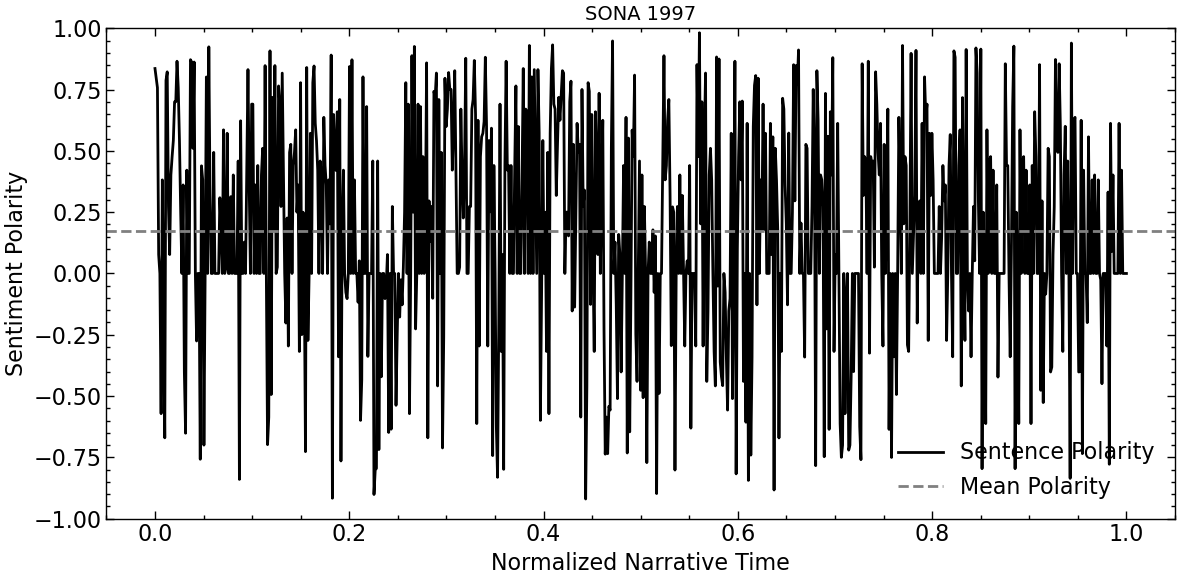

"2"
Number of sentences detected: 291
------------------------------
0.0 0.3818
0.0034482758620689655 0.0
0.006896551724137931 0.0
0.010344827586206896 0.3612
0.013793103448275862 -0.4404
0.017241379310344827 0.0
0.020689655172413793 0.0
0.02413793103448276 -0.296
0.027586206896551724 0.3182
0.03103448275862069 0.3818
0.034482758620689655 0.7506
0.03793103448275862 0.2263
0.041379310344827586 -0.6428
0.04482758620689655 0.0
0.04827586206896552 0.0
0.05172413793103448 0.6249
0.05517241379310345 0.7783
0.05862068965517241 0.6808
0.06206896551724138 0.8573
0.06551724137931035 0.4215
0.06896551724137931 0.8885
0.07241379310344828 -0.3595
0.07586206896551724 -0.5423
0.07931034482758621 0.7003
0.08275862068965517 0.4019
0.08620689655172414 0.0
0.0896551724137931 0.4588
0.09310344827586207 0.4767
0.09655172413793103 0.0
0.1 0.4019
0.10344827586206896 -0.6597
0.10689655172413794 0.631
0.1103448275862069 -0.7351
0.11379310344827587 0.0
0.11724137931034483 0.0
0.1206896551724138 -0.4201
0.124137

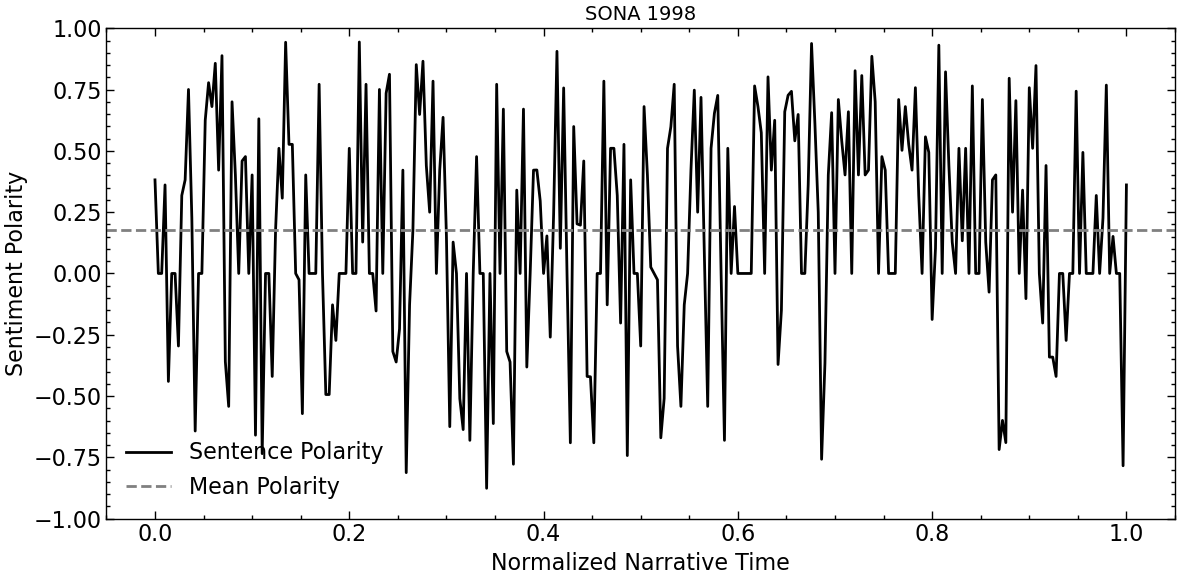

"3"
Number of sentences detected: 115
------------------------------
0.0 0.6476
0.008771929824561403 0.0
0.017543859649122806 0.3612
0.02631578947368421 -0.8151
0.03508771929824561 0.7384
0.043859649122807015 0.0
0.05263157894736842 0.0
0.06140350877192982 0.0
0.07017543859649122 0.0
0.07894736842105263 0.7845
0.08771929824561403 0.0
0.09649122807017543 -0.6597
0.10526315789473684 -0.395
0.11403508771929824 0.0
0.12280701754385964 0.4019
0.13157894736842105 0.6249
0.14035087719298245 -0.3182
0.14912280701754385 0.0
0.15789473684210525 0.1531
0.16666666666666666 -0.6597
0.17543859649122806 0.892
0.18421052631578946 0.899
0.19298245614035087 -0.25
0.20175438596491227 0.0
0.21052631578947367 0.0
0.21929824561403508 -0.3182
0.22807017543859648 -0.2732
0.23684210526315788 -0.3612
0.24561403508771928 0.4215
0.2543859649122807 0.4215
0.2631578947368421 -0.926
0.2719298245614035 -0.7184
0.2807017543859649 -0.5574
0.2894736842105263 -0.5719
0.2982456140350877 0.3089
0.30701754385964913 0.443
0.

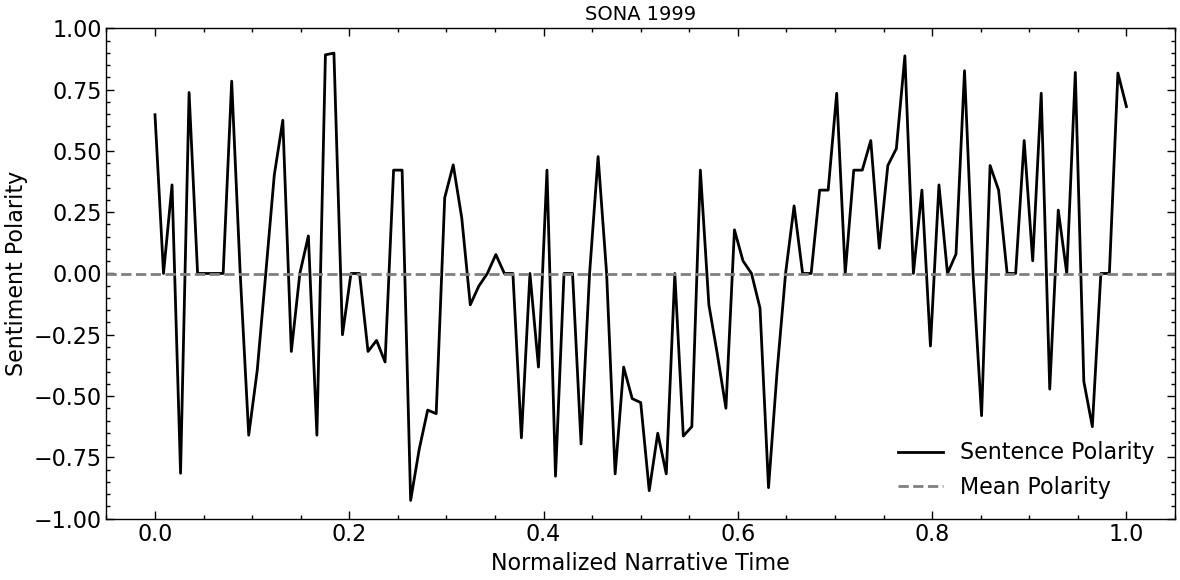

"4"
Number of sentences detected: 325
------------------------------
0.0 0.8932
0.0030864197530864196 0.0
0.006172839506172839 0.1027
0.009259259259259259 0.0
0.012345679012345678 0.0
0.015432098765432098 -0.5859
0.018518518518518517 0.5267
0.021604938271604937 0.6705
0.024691358024691357 0.0
0.027777777777777776 0.1901
0.030864197530864196 0.0
0.033950617283950615 0.0
0.037037037037037035 0.3612
0.040123456790123455 0.3869
0.043209876543209874 0.34
0.046296296296296294 0.0
0.04938271604938271 -0.2023
0.05246913580246913 0.0
0.05555555555555555 -0.2263
0.05864197530864197 -0.6597
0.06172839506172839 0.1027
0.06481481481481481 0.0
0.06790123456790123 0.296
0.07098765432098765 0.25
0.07407407407407407 0.5563
0.07716049382716049 0.0
0.08024691358024691 0.2732
0.08333333333333333 -0.4404
0.08641975308641975 0.0
0.08950617283950617 0.0
0.09259259259259259 0.5267
0.09567901234567901 0.0
0.09876543209876543 -0.3415
0.10185185185185185 0.0
0.10493827160493827 0.0
0.10802469135802469 0.4019
0.1

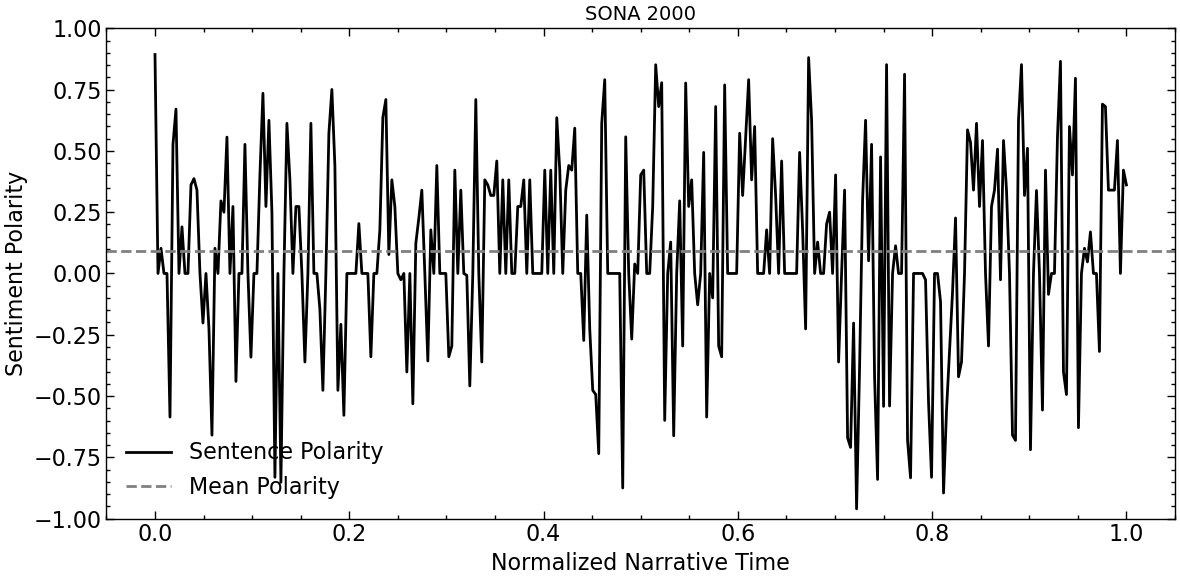

"5"
Number of sentences detected: 282
------------------------------
0.0 0.4389
0.0035587188612099642 0.4389
0.0071174377224199285 0.2732
0.010676156583629894 0.2716
0.014234875444839857 -0.296
0.017793594306049824 0.6369
0.021352313167259787 -0.4215
0.02491103202846975 -0.3182
0.028469750889679714 0.4404
0.03202846975088968 0.0
0.03558718861209965 0.25
0.03914590747330961 0.0
0.042704626334519574 0.34
0.046263345195729534 0.0
0.0498220640569395 0.802
0.05338078291814947 -0.5994
0.05693950177935943 0.7579
0.060498220640569395 0.6369
0.06405693950177936 0.34
0.06761565836298933 0.4588
0.0711743772241993 0.0
0.07473309608540925 0.5994
0.07829181494661921 0.0
0.08185053380782918 0.5574
0.08540925266903915 0.34
0.08896797153024912 0.2023
0.09252669039145907 0.3818
0.09608540925266904 0.0
0.099644128113879 0.3612
0.10320284697508897 0.1779
0.10676156583629894 0.7096
0.1103202846975089 0.0
0.11387900355871886 0.7184
0.11743772241992882 0.34
0.12099644128113879 0.0
0.12455516014234876 0.0
0.1

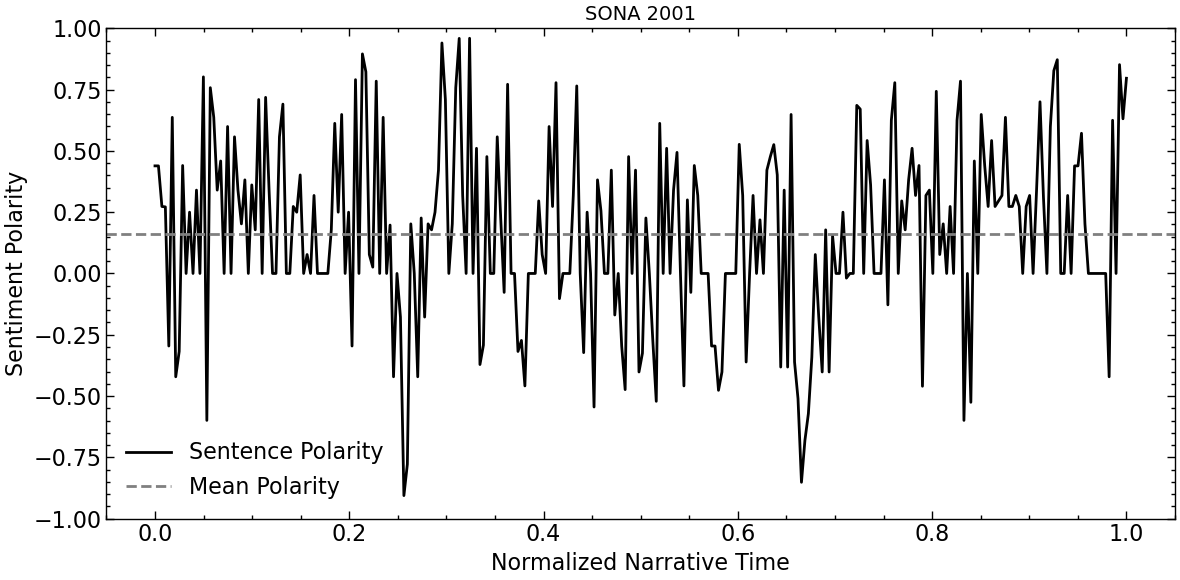

"6"
Number of sentences detected: 204
------------------------------
0.0 0.4389
0.0049261083743842365 0.4389
0.009852216748768473 0.0
0.014778325123152709 0.6486
0.019704433497536946 -0.0772
0.024630541871921183 0.7441
0.029556650246305417 0.0
0.034482758620689655 0.4404
0.03940886699507389 0.4215
0.04433497536945813 0.5574
0.04926108374384237 0.296
0.054187192118226604 0.1531
0.059113300492610835 -0.6164
0.06403940886699508 0.0
0.06896551724137931 0.6369
0.07389162561576355 0.0
0.07881773399014778 0.3612
0.08374384236453201 0.6486
0.08866995073891626 0.3612
0.09359605911330049 0.0
0.09852216748768473 0.0
0.10344827586206896 0.4389
0.10837438423645321 0.4019
0.11330049261083744 -0.0323
0.11822660098522167 -0.7506
0.12315270935960591 0.0
0.12807881773399016 -0.4019
0.1330049261083744 -0.5719
0.13793103448275862 0.0
0.14285714285714285 0.0
0.1477832512315271 0.4201
0.15270935960591134 0.8479
0.15763546798029557 0.0
0.1625615763546798 -0.0258
0.16748768472906403 0.0
0.1724137931034483 -0.

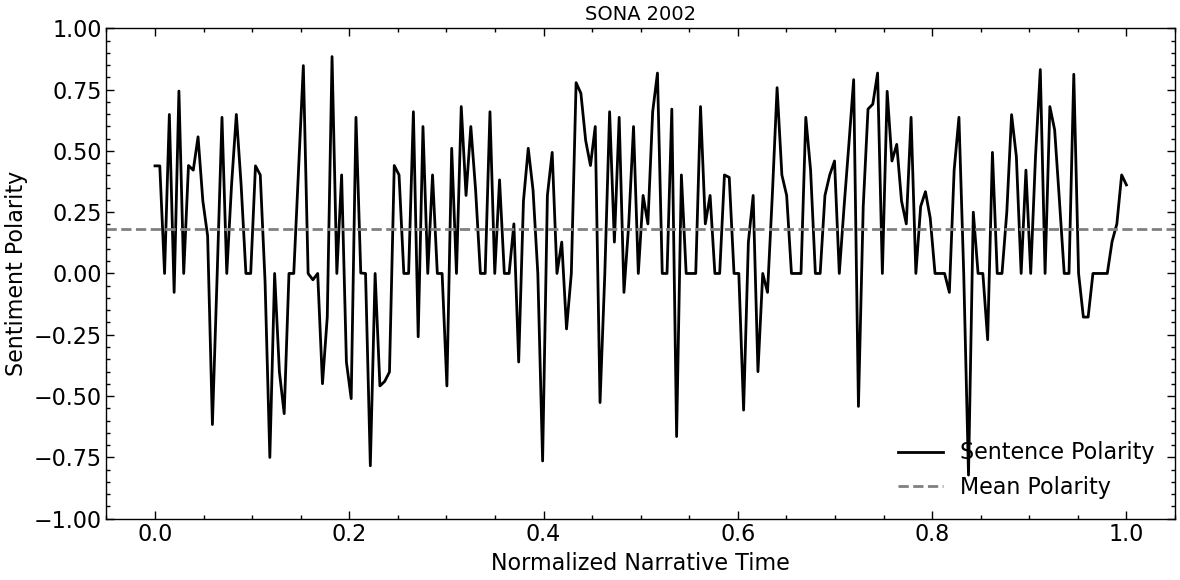

"7"
Number of sentences detected: 248
------------------------------
0.0 0.4939
0.004048582995951417 0.0
0.008097165991902834 0.886
0.012145748987854251 0.5719
0.016194331983805668 0.6478
0.020242914979757085 0.0
0.024291497975708502 0.836
0.02834008097165992 0.6361
0.032388663967611336 0.0
0.03643724696356275 0.0
0.04048582995951417 0.3182
0.044534412955465584 0.4767
0.048582995951417005 0.0
0.05263157894736842 0.4215
0.05668016194331984 0.3182
0.06072874493927125 0.4939
0.06477732793522267 0.4939
0.06882591093117409 0.0
0.0728744939271255 0.2023
0.07692307692307693 -0.5106
0.08097165991902834 0.7506
0.08502024291497975 0.0
0.08906882591093117 0.3818
0.0931174089068826 0.5574
0.09716599190283401 -0.3182
0.10121457489878542 0.4404
0.10526315789473684 0.3182
0.10931174089068826 0.0
0.11336032388663968 0.802
0.11740890688259109 0.7184
0.1214574898785425 0.5994
0.12550607287449392 0.296
0.12955465587044535 0.5859
0.13360323886639677 0.4019
0.13765182186234817 0.0
0.1417004048582996 0.4404

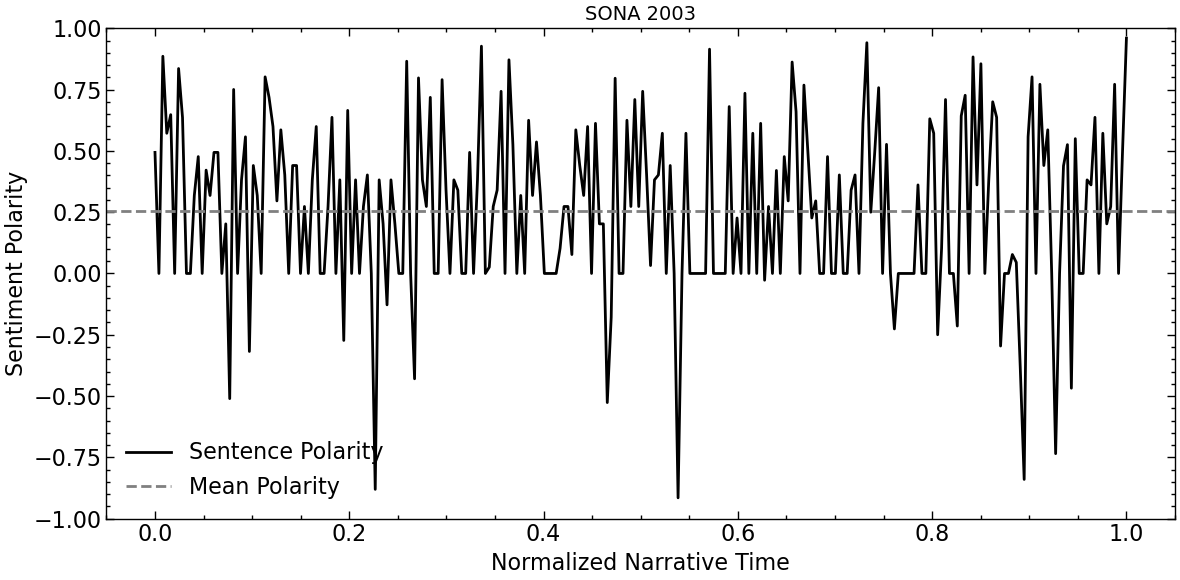

"8"
Number of sentences detected: 448
------------------------------
0.0 0.7783
0.0022371364653243847 -0.128
0.0044742729306487695 0.5709
0.006711409395973154 0.0
0.008948545861297539 0.0
0.011185682326621925 0.2263
0.013422818791946308 0.3818
0.015659955257270694 0.34
0.017897091722595078 0.4019
0.020134228187919462 0.128
0.02237136465324385 0.0
0.024608501118568233 0.7964
0.026845637583892617 0.0
0.029082774049217 0.0
0.03131991051454139 0.5267
0.03355704697986577 0.5859
0.035794183445190156 0.0
0.03803131991051454 0.0
0.040268456375838924 0.0
0.042505592841163314 0.0
0.0447427293064877 0.2732
0.04697986577181208 0.7717
0.049217002237136466 0.2732
0.05145413870246085 0.0
0.053691275167785234 0.2732
0.05592841163310962 0.0
0.058165548098434 0.905
0.06040268456375839 0.4215
0.06263982102908278 0.0
0.06487695749440715 0.2732
0.06711409395973154 -0.3182
0.06935123042505593 0.0
0.07158836689038031 0.0
0.0738255033557047 0.0
0.07606263982102908 0.1779
0.07829977628635347 0.5994
0.080536912

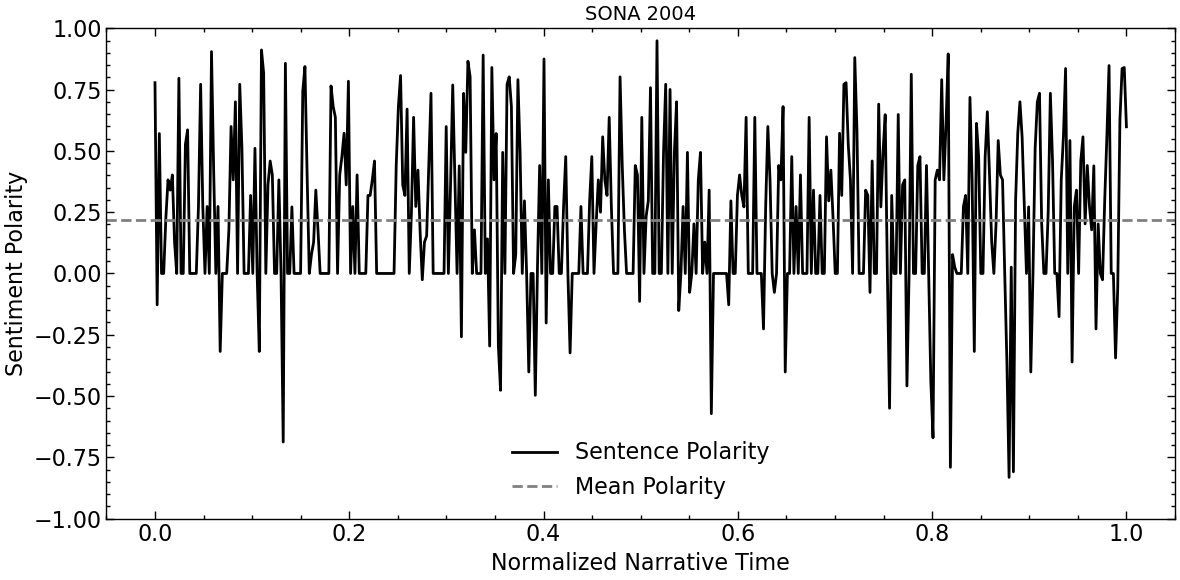

"9"
Number of sentences detected: 515
------------------------------
0.0 0.0
0.0019455252918287938 0.4389
0.0038910505836575876 0.0
0.005836575875486381 0.4215
0.007782101167315175 0.7096
0.009727626459143969 -0.7096
0.011673151750972763 0.5106
0.013618677042801557 0.88
0.01556420233463035 0.4767
0.017509727626459144 0.7184
0.019455252918287938 0.6705
0.021400778210116732 0.0
0.023346303501945526 -0.5719
0.02529182879377432 0.0
0.027237354085603113 0.0
0.029182879377431907 -0.1027
0.0311284046692607 0.9062
0.033073929961089495 0.7351
0.03501945525291829 0.3818
0.03696498054474708 0.9371
0.038910505836575876 0.0
0.04085603112840467 0.3867
0.042801556420233464 0.0
0.04474708171206226 0.3818
0.04669260700389105 0.0
0.048638132295719845 0.0
0.05058365758754864 0.0
0.05252918287937743 0.4215
0.054474708171206226 0.0
0.05642023346303502 0.0
0.058365758754863814 0.0
0.06031128404669261 0.0258
0.0622568093385214 0.0
0.06420233463035019 0.0
0.06614785992217899 0.5106
0.06809338521400778 0.3818


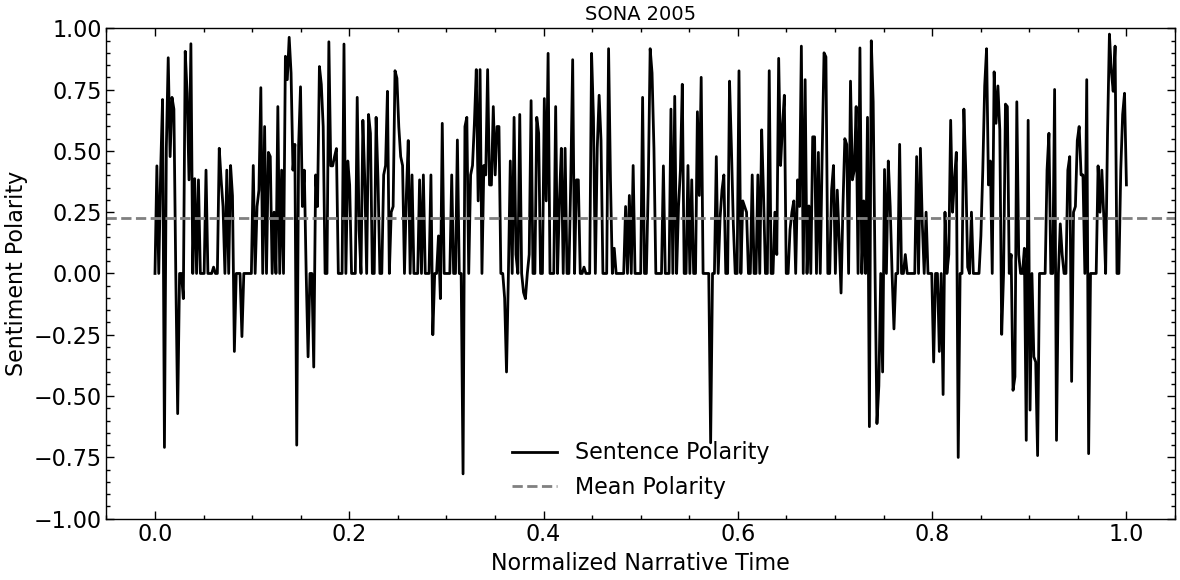

"10"
Number of sentences detected: 382
------------------------------
0.0 0.5974
0.0026246719160104987 0.0
0.005249343832020997 0.0
0.007874015748031496 0.0
0.010498687664041995 0.4019
0.013123359580052493 0.4939
0.015748031496062992 0.4767
0.01837270341207349 0.4939
0.02099737532808399 0.25
0.023622047244094488 0.5106
0.026246719160104987 0.296
0.028871391076115485 0.743
0.031496062992125984 0.8658
0.03412073490813648 0.6705
0.03674540682414698 0.7837
0.03937007874015748 0.6962
0.04199475065616798 0.5859
0.04461942257217848 0.0387
0.047244094488188976 0.8658
0.049868766404199474 0.7783
0.05249343832020997 0.8176
0.05511811023622047 0.0
0.05774278215223097 0.1779
0.06036745406824147 0.0
0.06299212598425197 0.4019
0.06561679790026247 0.0
0.06824146981627296 0.6597
0.07086614173228346 0.6597
0.07349081364829396 0.128
0.07611548556430446 0.0
0.07874015748031496 0.3182
0.08136482939632546 0.4019
0.08398950131233596 0.6808
0.08661417322834646 0.0
0.08923884514435695 0.4939
0.091863517060367

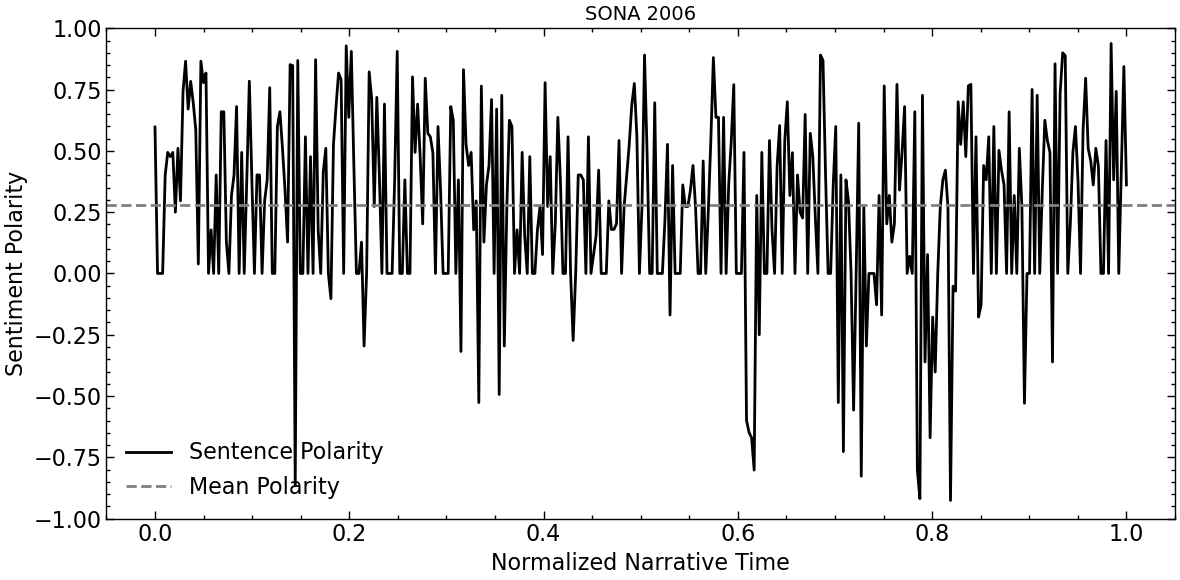

"11"
Number of sentences detected: 677
------------------------------
0.0 0.4389
0.0014792899408284023 0.0
0.0029585798816568047 0.6908
0.004437869822485207 0.4215
0.005917159763313609 0.1531
0.0073964497041420114 0.0
0.008875739644970414 0.4767
0.010355029585798817 0.5423
0.011834319526627219 0.7184
0.013313609467455622 0.2484
0.014792899408284023 0.0
0.016272189349112426 0.4019
0.01775147928994083 0.0
0.019230769230769232 0.0
0.020710059171597635 0.7096
0.022189349112426034 0.0258
0.023668639053254437 0.3818
0.02514792899408284 0.0
0.026627218934911243 0.7184
0.028106508875739646 0.4215
0.029585798816568046 0.802
0.03106508875739645 0.0
0.03254437869822485 0.0
0.034023668639053255 0.0
0.03550295857988166 0.0
0.03698224852071006 0.0
0.038461538461538464 0.4019
0.03994082840236687 0.3612
0.04142011834319527 0.2732
0.042899408284023666 -0.4168
0.04437869822485207 0.6908
0.04585798816568047 0.5859
0.047337278106508875 0.4588
0.04881656804733728 0.0
0.05029585798816568 0.3182
0.0517751479

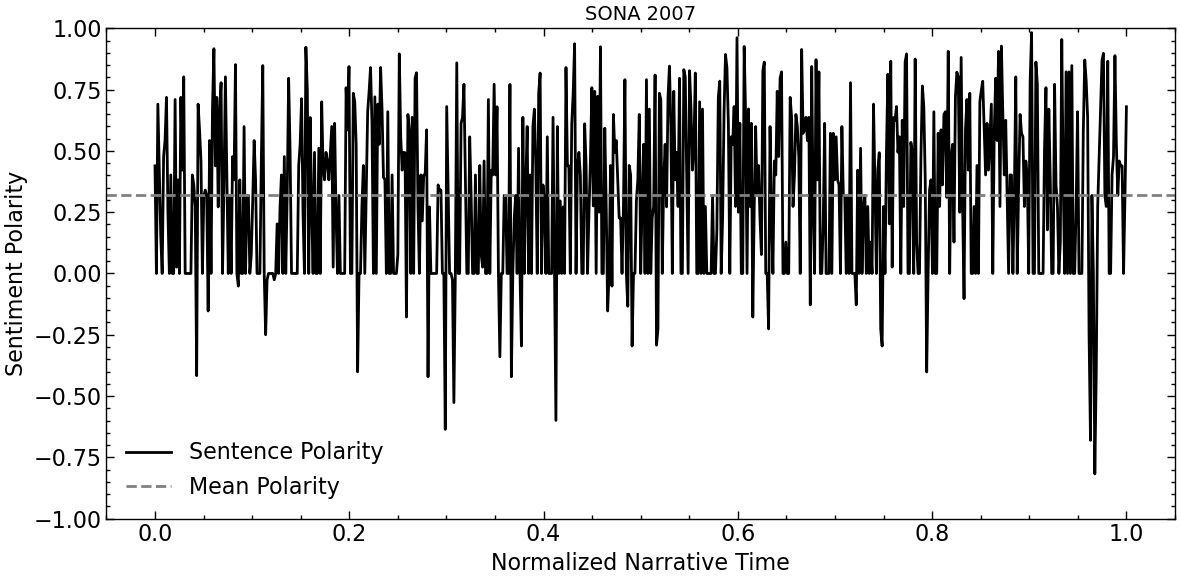

"12"
Number of sentences detected: 333
------------------------------
0.0 0.0
0.0030120481927710845 0.6696
0.006024096385542169 0.9041
0.009036144578313253 0.0387
0.012048192771084338 0.2484
0.015060240963855422 0.0
0.018072289156626505 0.25
0.02108433734939759 0.0
0.024096385542168676 0.4019
0.02710843373493976 0.0
0.030120481927710843 0.4019
0.03313253012048193 0.0
0.03614457831325301 0.6705
0.0391566265060241 0.0
0.04216867469879518 0.0
0.045180722891566265 0.4201
0.04819277108433735 0.1779
0.05120481927710843 0.7096
0.05421686746987952 0.6486
0.0572289156626506 0.6808
0.060240963855421686 0.34
0.06325301204819277 0.0
0.06626506024096386 0.1779
0.06927710843373494 0.0
0.07228915662650602 0.4215
0.07530120481927711 -0.25
0.0783132530120482 -0.5719
0.08132530120481928 0.0
0.08433734939759036 0.0
0.08734939759036145 0.0
0.09036144578313253 0.8625
0.09337349397590361 0.7184
0.0963855421686747 0.1027
0.09939759036144578 0.0
0.10240963855421686 0.0
0.10542168674698796 0.743
0.108433734939

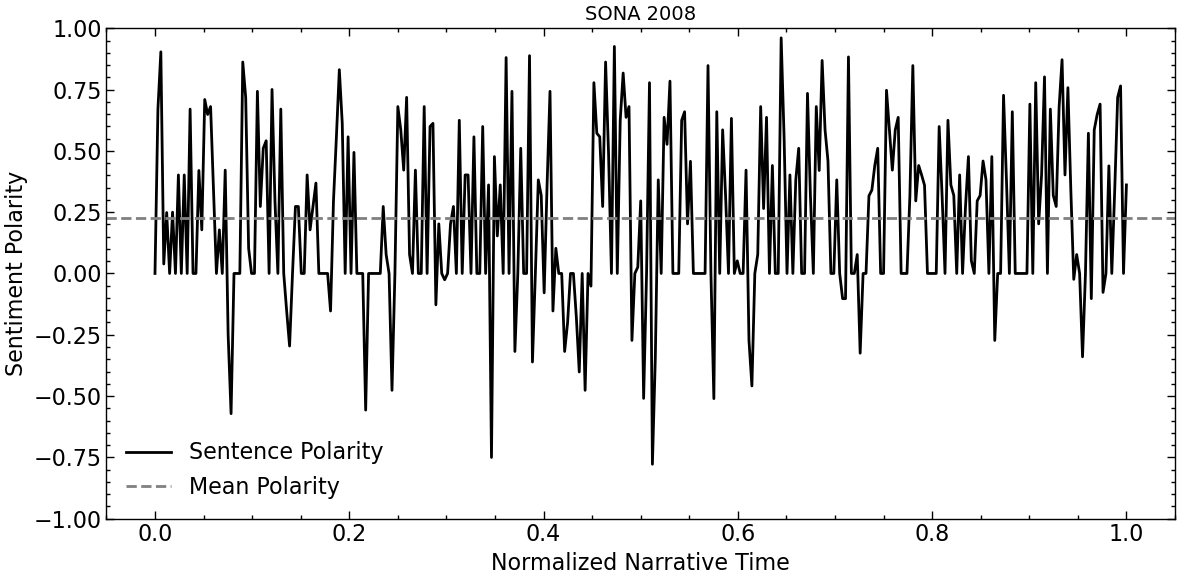

"13"
Number of sentences detected: 302
------------------------------
0.0 -0.4199
0.0033222591362126247 -0.743
0.006644518272425249 -0.4033
0.009966777408637873 0.0
0.013289036544850499 0.0
0.016611295681063124 -0.8179
0.019933554817275746 0.8176
0.023255813953488372 0.1154
0.026578073089700997 -0.6249
0.029900332225913623 0.5236
0.03322259136212625 0.6124
0.036544850498338874 0.0
0.03986710963455149 -0.6249
0.04318936877076412 0.6486
0.046511627906976744 -0.296
0.04983388704318937 -0.6124
0.053156146179401995 0.2023
0.05647840531561462 0.0
0.059800664451827246 -0.5259
0.06312292358803986 0.0
0.0664451827242525 0.7227
0.06976744186046512 0.2023
0.07308970099667775 0.0
0.07641196013289037 0.4497
0.07973421926910298 0.4019
0.08305647840531562 0.6369
0.08637873754152824 0.2023
0.08970099667774087 0.1027
0.09302325581395349 0.6588
0.09634551495016612 0.4389
0.09966777408637874 0.4389
0.10299003322259136 0.296
0.10631229235880399 0.4767
0.10963455149501661 0.4215
0.11295681063122924 0.5574


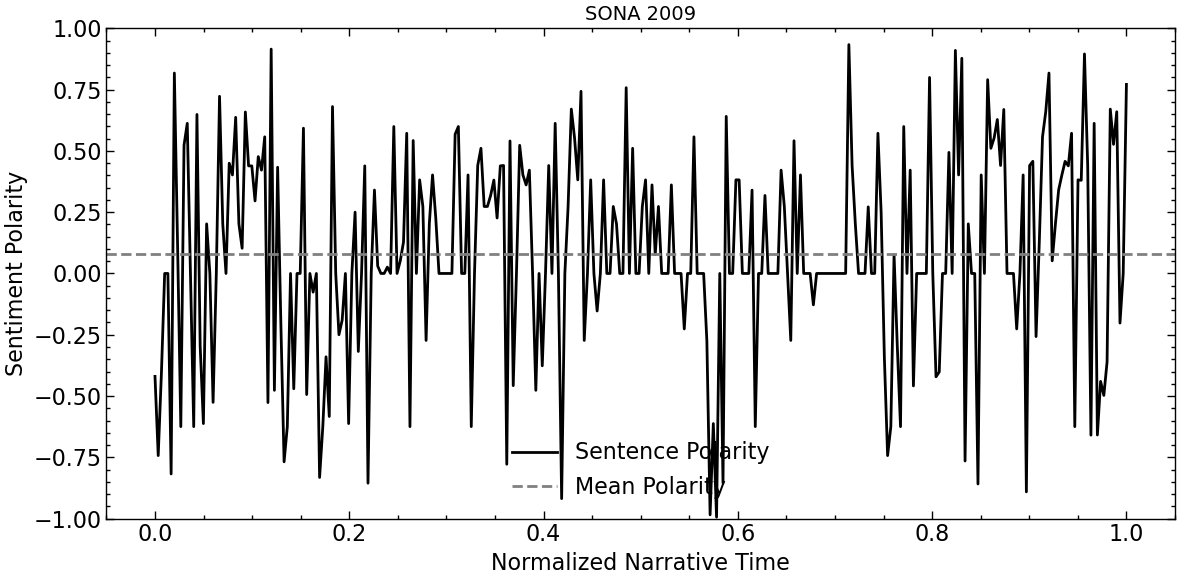

"14"
Number of sentences detected: 404
------------------------------
0.0 0.0
0.0024813895781637717 -0.0498
0.004962779156327543 -0.6705
0.007444168734491315 -0.743
0.009925558312655087 -0.2899
0.01240694789081886 0.1027
0.01488833746898263 0.0
0.017369727047146403 0.9001
0.019851116625310174 0.5994
0.022332506203473945 0.9201
0.02481389578163772 0.6124
0.02729528535980149 0.8481
0.02977667493796526 0.802
0.03225806451612903 0.743
0.034739454094292806 0.2023
0.03722084367245657 0.4404
0.03970223325062035 0.7783
0.04218362282878412 0.4588
0.04466501240694789 0.0
0.04714640198511166 0.0
0.04962779156327544 0.0
0.052109181141439205 0.2716
0.05459057071960298 0.6908
0.05707196029776675 0.2732
0.05955334987593052 0.296
0.062034739454094295 0.4767
0.06451612903225806 0.2732
0.06699751861042183 0.2732
0.06947890818858561 0.0
0.07196029776674938 0.0
0.07444168734491315 0.0
0.07692307692307693 0.4215
0.0794044665012407 0.5797
0.08188585607940446 0.0
0.08436724565756824 0.3382
0.0868486352357320

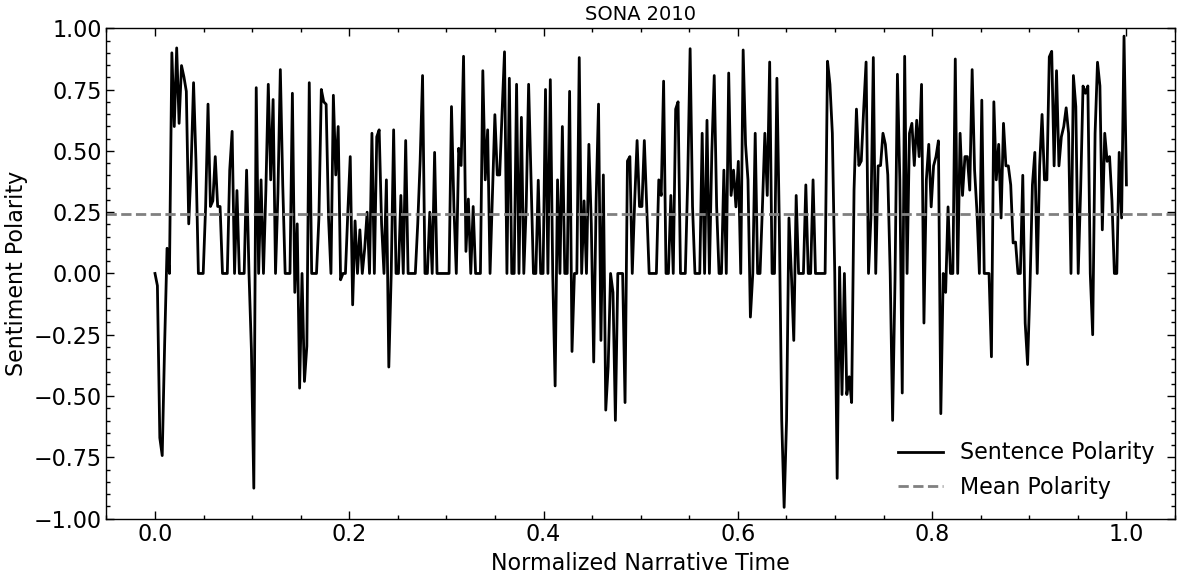

"15"
Number of sentences detected: 328
------------------------------
0.0 0.4389
0.0030581039755351682 0.4389
0.0061162079510703364 0.0
0.009174311926605505 0.5256
0.012232415902140673 0.0
0.01529051987767584 0.6249
0.01834862385321101 0.0
0.021406727828746176 -0.34
0.024464831804281346 0.2452
0.027522935779816515 0.6124
0.03058103975535168 0.6808
0.03363914373088685 0.0
0.03669724770642202 0.34
0.039755351681957186 0.7906
0.04281345565749235 0.3818
0.045871559633027525 0.4215
0.04892966360856269 0.0
0.05198776758409786 0.4939
0.05504587155963303 0.4215
0.0581039755351682 0.0
0.06116207951070336 0.6369
0.06422018348623854 0.0
0.0672782874617737 0.6249
0.07033639143730887 0.2732
0.07339449541284404 0.0
0.0764525993883792 0.2732
0.07951070336391437 0.2732
0.08256880733944955 -0.0772
0.0856269113149847 0.4767
0.08868501529051988 0.0
0.09174311926605505 0.4767
0.09480122324159021 0.0
0.09785932721712538 0.2732
0.10091743119266056 0.0
0.10397553516819572 0.0
0.10703363914373089 0.0
0.110091

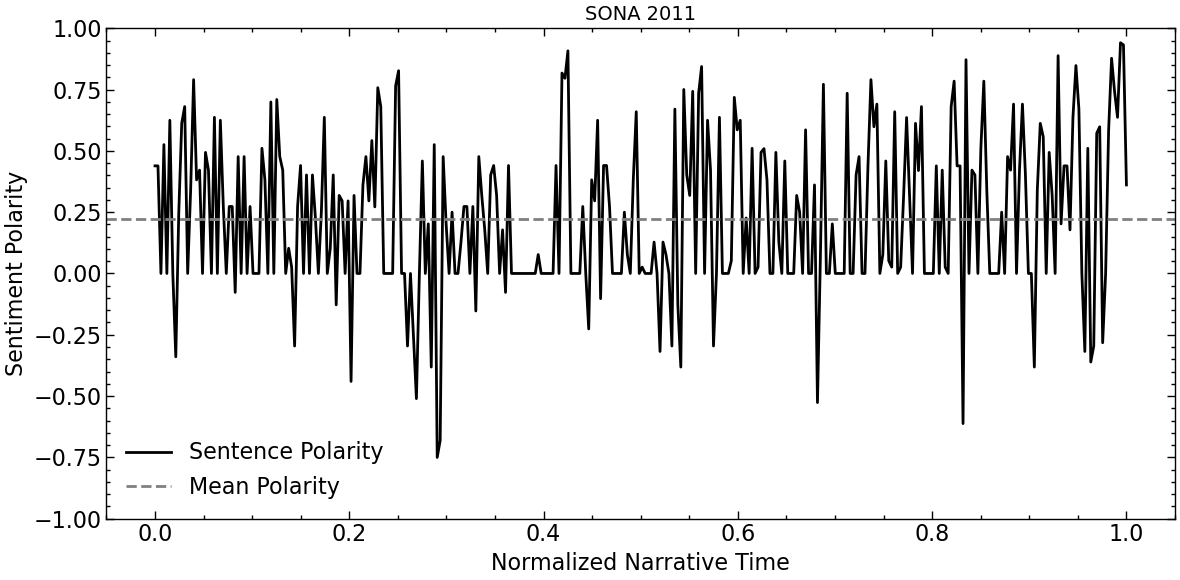

"16"
Number of sentences detected: 1122
------------------------------
0.0 0.9042
0.0008920606601248885 0.0
0.001784121320249777 0.9169
0.0026761819803746653 0.1779
0.003568242640499554 0.0772
0.0044603033006244425 0.0
0.0053523639607493305 0.2732
0.006244424620874219 0.0
0.007136485280999108 0.0
0.008028545941123996 0.1779
0.008920606601248885 0.0
0.009812667261373774 0.8834
0.010704727921498661 0.0
0.01159678858162355 0.4019
0.012488849241748439 0.8689
0.013380909901873328 0.4404
0.014272970561998216 0.6124
0.015165031222123104 0.9538
0.016057091882247992 0.7351
0.01694915254237288 0.0
0.01784121320249777 0.0
0.01873327386262266 0.9337
0.019625334522747548 0.765
0.020517395182872437 0.4019
0.021409455842997322 0.0
0.02230151650312221 0.4404
0.0231935771632471 0.5859
0.02408563782337199 0.6249
0.024977698483496878 0.6369
0.025869759143621766 0.4939
0.026761819803746655 0.5423
0.027653880463871544 -0.6249
0.028545941123996433 0.2263
0.029438001784121322 0.0
0.030330062444246207 0.802
0

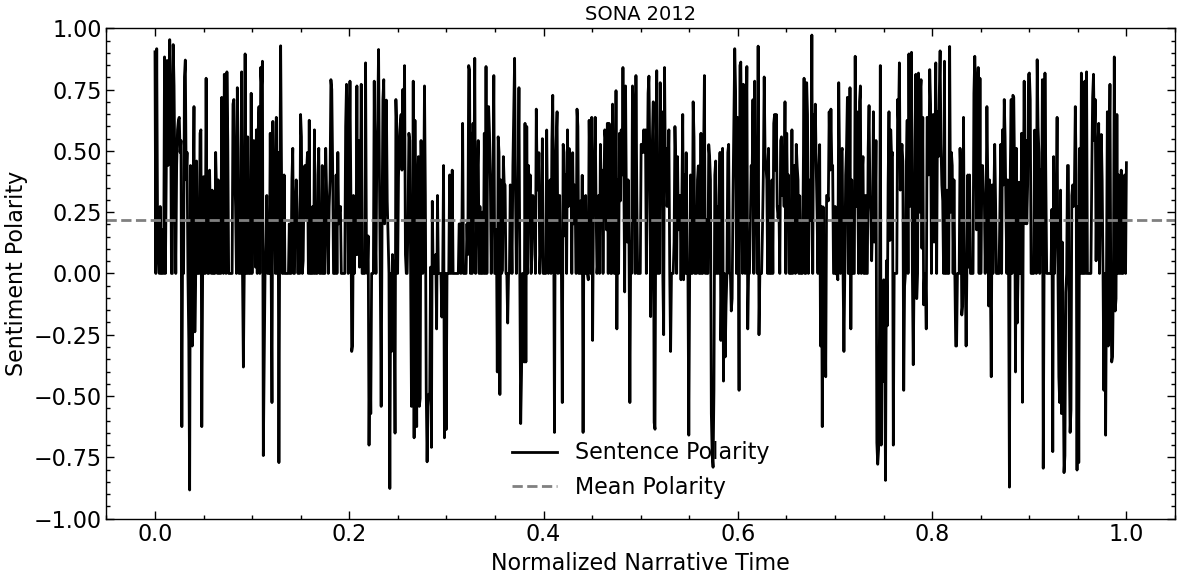

"17"
Number of sentences detected: 358
------------------------------
0.0 0.4389
0.0028011204481792717 0.4389
0.0056022408963585435 0.0
0.008403361344537815 0.5106
0.011204481792717087 0.0
0.014005602240896359 0.0
0.01680672268907563 0.0
0.0196078431372549 -0.4767
0.022408963585434174 0.3612
0.025210084033613446 0.1779
0.028011204481792718 0.0
0.03081232492997199 0.0
0.03361344537815126 0.296
0.036414565826330535 0.0
0.0392156862745098 0.836
0.04201680672268908 -0.5423
0.04481792717086835 -0.6249
0.047619047619047616 -0.6249
0.05042016806722689 0.0964
0.05322128851540616 0.296
0.056022408963585436 0.0
0.058823529411764705 0.4389
0.06162464985994398 0.6369
0.06442577030812324 0.875
0.06722689075630252 0.0
0.0700280112044818 0.0
0.07282913165266107 0.25
0.07563025210084033 0.0
0.0784313725490196 0.0
0.08123249299719888 0.0
0.08403361344537816 0.0
0.08683473389355742 0.2023
0.0896358543417367 0.6369
0.09243697478991597 0.3818
0.09523809523809523 0.3182
0.09803921568627451 0.0
0.1008403361

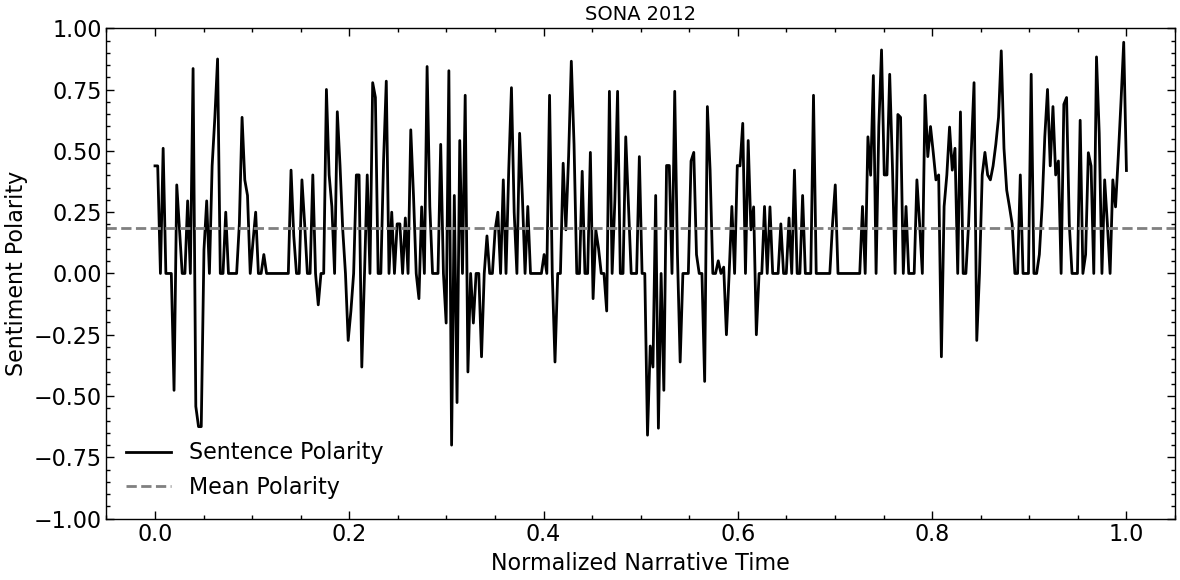

"18"
Number of sentences detected: 358
------------------------------
0.0 0.5983
0.0028011204481792717 0.0
0.0056022408963585435 0.296
0.008403361344537815 0.5859
0.011204481792717087 0.7906
0.014005602240896359 0.7003
0.01680672268907563 0.4767
0.0196078431372549 0.4215
0.022408963585434174 0.4588
0.025210084033613446 0.34
0.028011204481792718 0.8519
0.03081232492997199 0.3818
0.03361344537815126 0.7003
0.036414565826330535 0.5532
0.0392156862745098 0.4389
0.04201680672268908 0.7712
0.04481792717086835 0.7263
0.047619047619047616 0.8932
0.05042016806722689 0.0
0.05322128851540616 0.5859
0.056022408963585436 0.296
0.058823529411764705 0.2023
0.06162464985994398 0.2382
0.06442577030812324 0.4404
0.06722689075630252 0.7351
0.0700280112044818 0.0
0.07282913165266107 0.4588
0.07563025210084033 0.0
0.0784313725490196 0.0772
0.08123249299719888 0.2023
0.08403361344537816 0.765
0.08683473389355742 0.4215
0.0896358543417367 0.8519
0.09243697478991597 0.0772
0.09523809523809523 0.34
0.098039215

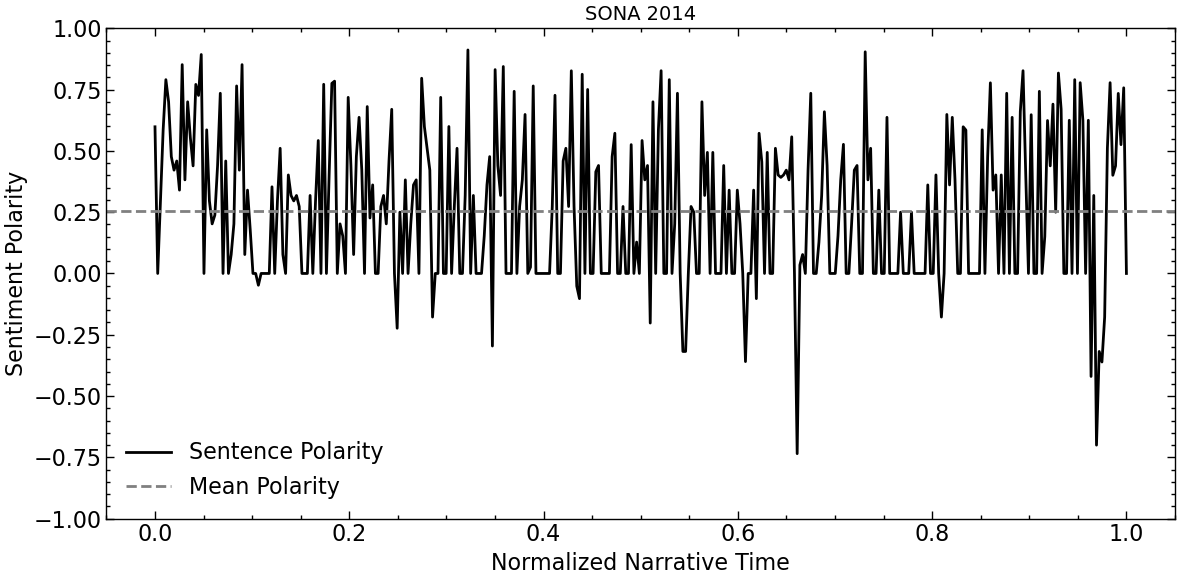

"19"
Number of sentences detected: 354
------------------------------
0.0 0.4389
0.0028328611898017 0.0
0.0056657223796034 0.5267
0.0084985835694051 0.4767
0.0113314447592068 0.7096
0.014164305949008499 0.6597
0.0169971671388102 0.34
0.019830028328611898 0.0
0.0226628895184136 0.2023
0.025495750708215296 0.0
0.028328611898016998 0.0772
0.031161473087818695 0.4588
0.0339943342776204 0.4404
0.036827195467422094 -0.1531
0.039660056657223795 -0.1027
0.042492917847025496 0.0
0.0453257790368272 0.0
0.04815864022662889 0.4019
0.05099150141643059 0.8481
0.053824362606232294 -0.128
0.056657223796033995 -0.1045
0.059490084985835696 0.0
0.06232294617563739 0.3818
0.06515580736543909 0.4389
0.0679886685552408 0.5267
0.0708215297450425 0.0
0.07365439093484419 0.2732
0.0764872521246459 0.802
0.07932011331444759 0.0772
0.0821529745042493 0.5719
0.08498583569405099 -0.2263
0.08781869688385269 0.5994
0.0906515580736544 0.8465
0.09348441926345609 0.0
0.09631728045325778 -0.4404
0.09915014164305949 0.25


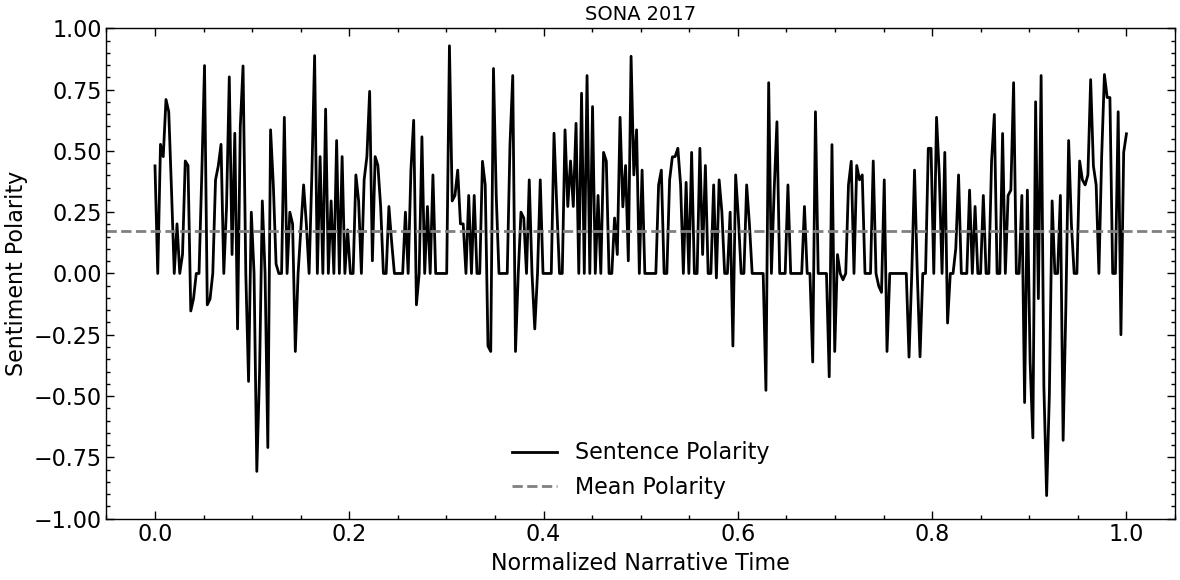

"20"
Number of sentences detected: 317
------------------------------
0.0 0.6369
0.0031645569620253164 0.0
0.006329113924050633 0.4404
0.00949367088607595 0.2023
0.012658227848101266 0.0
0.015822784810126583 0.0
0.0189873417721519 0.0
0.022151898734177215 0.128
0.02531645569620253 0.4939
0.028481012658227847 0.25
0.03164556962025317 0.25
0.03481012658227848 0.0
0.0379746835443038 0.0
0.04113924050632911 0.5859
0.04430379746835443 0.9169
0.04746835443037975 0.34
0.05063291139240506 0.0
0.05379746835443038 0.0
0.056962025316455694 0.4939
0.060126582278481014 -0.4404
0.06329113924050633 0.3818
0.06645569620253164 0.0
0.06962025316455696 0.5859
0.07278481012658228 0.5574
0.0759493670886076 0.6994
0.07911392405063292 0.0
0.08227848101265822 0.0
0.08544303797468354 0.0
0.08860759493670886 0.4404
0.09177215189873418 0.6597
0.0949367088607595 0.0
0.0981012658227848 0.0
0.10126582278481013 0.1027
0.10443037974683544 -0.6249
0.10759493670886076 0.0
0.11075949367088607 0.6659
0.11392405063291139 

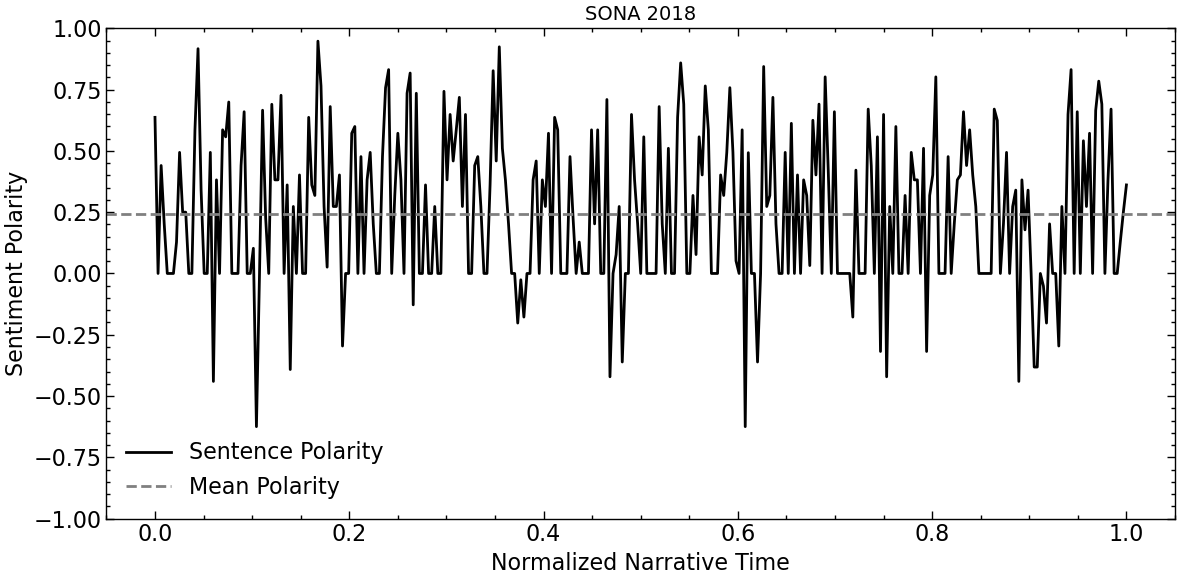

"21"
Number of sentences detected: 348
------------------------------
0.0 0.7088
0.002881844380403458 0.6249
0.005763688760806916 0.8689
0.008645533141210375 0.2023
0.011527377521613832 0.3182
0.01440922190201729 0.3818
0.01729106628242075 0.0
0.020172910662824207 0.4404
0.023054755043227664 0.2023
0.025936599423631124 0.0
0.02881844380403458 0.5106
0.03170028818443804 0.0
0.0345821325648415 0.0
0.037463976945244955 0.0
0.040345821325648415 0.296
0.043227665706051875 0.0
0.04610951008645533 0.5859
0.04899135446685879 0.296
0.05187319884726225 0.25
0.05475504322766571 0.0
0.05763688760806916 0.128
0.06051873198847262 0.7096
0.06340057636887608 0.9042
0.06628242074927954 0.4215
0.069164265129683 0.4389
0.07204610951008646 0.4939
0.07492795389048991 0.0
0.07780979827089338 0.34
0.08069164265129683 0.0
0.08357348703170028 0.0
0.08645533141210375 -0.6808
0.0893371757925072 -0.4019
0.09221902017291066 0.8176
0.09510086455331412 0.0
0.09798270893371758 0.1779
0.10086455331412104 0.0
0.1037463

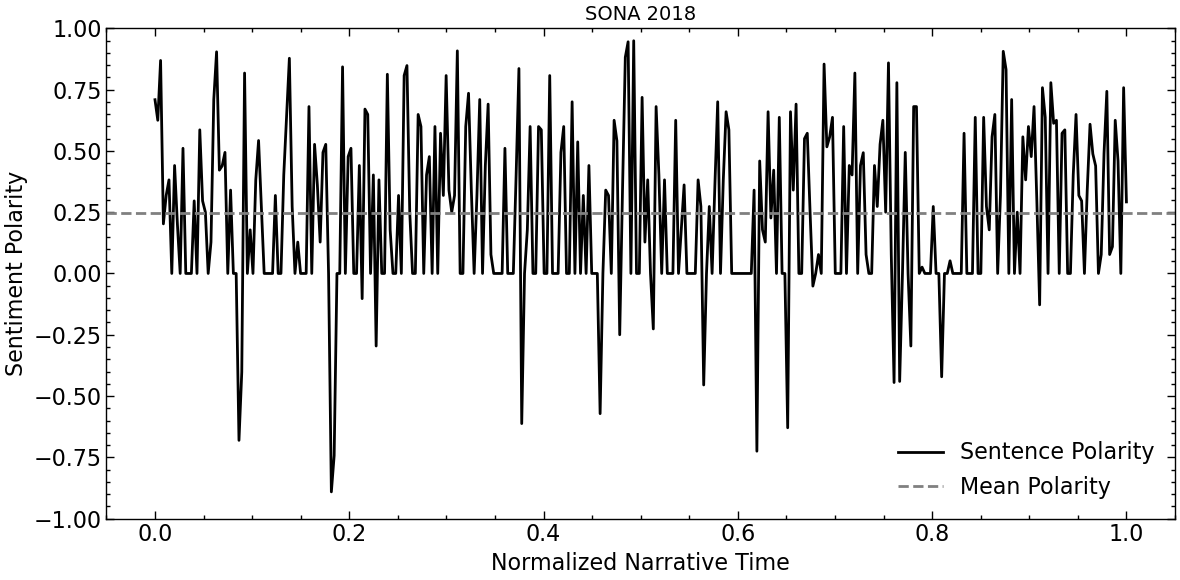

"22"
Number of sentences detected: 517
------------------------------
0.0 0.4389
0.001937984496124031 0.4389
0.003875968992248062 0.636
0.005813953488372093 0.2023
0.007751937984496124 0.25
0.009689922480620155 0.296
0.011627906976744186 0.9136
0.013565891472868217 0.8779
0.015503875968992248 0.0
0.01744186046511628 0.0
0.01937984496124031 0.0
0.02131782945736434 0.0
0.023255813953488372 0.0
0.025193798449612403 0.6486
0.027131782945736434 0.0
0.029069767441860465 0.25
0.031007751937984496 0.3612
0.03294573643410853 0.4767
0.03488372093023256 0.5423
0.03682170542635659 -0.3182
0.03875968992248062 0.5499
0.040697674418604654 0.3818
0.04263565891472868 0.7351
0.044573643410852716 0.0
0.046511627906976744 0.0
0.04844961240310078 0.4019
0.050387596899224806 0.4588
0.05232558139534884 0.6361
0.05426356589147287 0.6486
0.0562015503875969 0.0
0.05813953488372093 0.0
0.060077519379844964 0.4019
0.06201550387596899 0.6597
0.06395348837209303 0.6908
0.06589147286821706 -0.128
0.06782945736434108

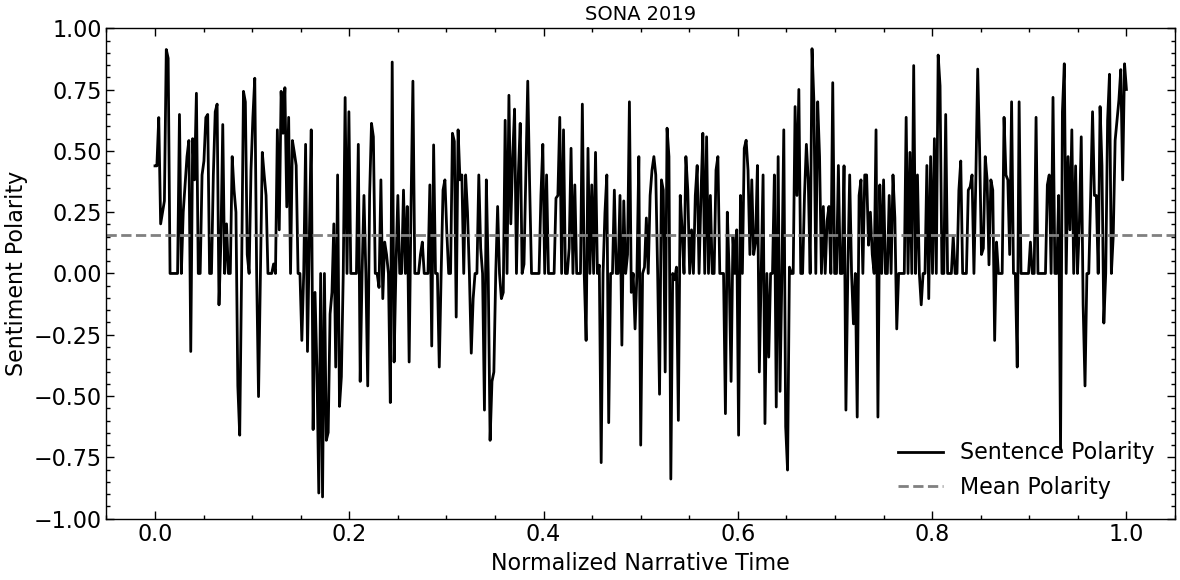

"23"
Number of sentences detected: 730
------------------------------
0.0 0.1531
0.0013717421124828531 -0.5106
0.0027434842249657062 0.3818
0.00411522633744856 0.2263
0.0054869684499314125 0.0772
0.006858710562414266 0.1779
0.00823045267489712 0.7184
0.009602194787379973 0.7717
0.010973936899862825 0.0
0.012345679012345678 -0.3612
0.013717421124828532 -0.3818
0.015089163237311385 0.0
0.01646090534979424 -0.3182
0.01783264746227709 0.0
0.019204389574759947 0.0
0.0205761316872428 0.0
0.02194787379972565 0.6597
0.023319615912208505 -0.4215
0.024691358024691357 -0.296
0.02606310013717421 0.0
0.027434842249657063 -0.3612
0.02880658436213992 -0.2919
0.03017832647462277 -0.6486
0.03155006858710562 0.0
0.03292181069958848 0.2023
0.03429355281207133 -0.3818
0.03566529492455418 -0.4588
0.037037037037037035 0.5859
0.038408779149519894 0.3612
0.039780521262002745 0.6345
0.0411522633744856 0.0
0.04252400548696845 0.0
0.0438957475994513 -0.1531
0.04526748971193416 0.6908
0.04663923182441701 0.0
0.04

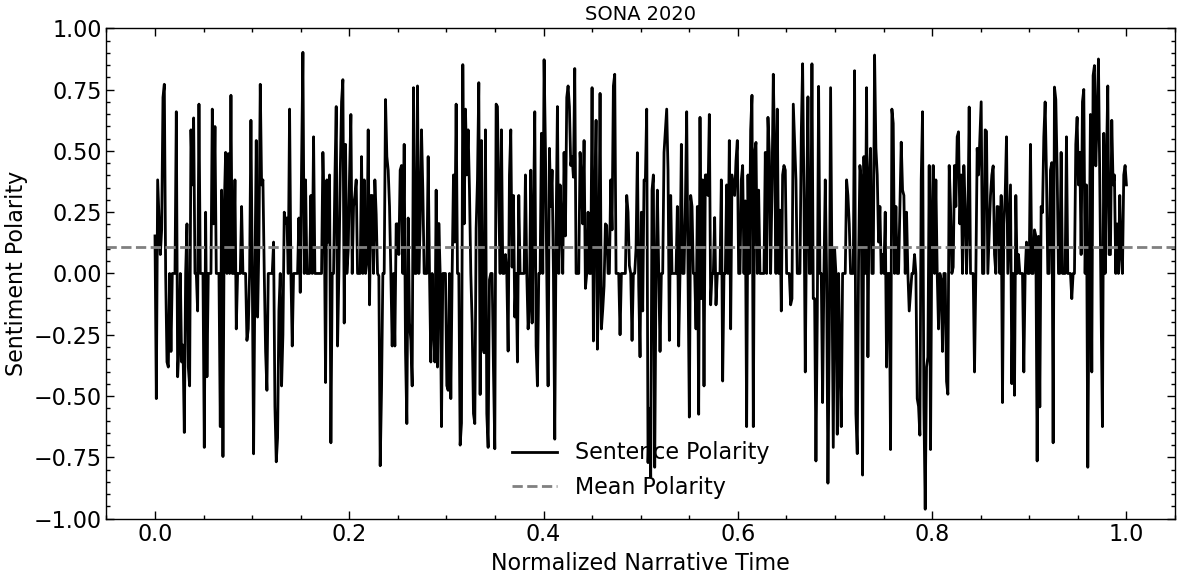

"24"
Number of sentences detected: 590
------------------------------
0.0 0.5411
0.001697792869269949 0.0
0.003395585738539898 0.7245
0.0050933786078098476 0.765
0.006791171477079796 0.7845
0.008488964346349746 0.6249
0.010186757215619695 0.4404
0.011884550084889643 0.6908
0.013582342954159592 0.5106
0.015280135823429542 0.1511
0.01697792869269949 0.9022
0.01867572156196944 0.0
0.02037351443123939 0.5994
0.022071307300509338 0.0
0.023769100169779286 0.05
0.025466893039049237 0.4404
0.027164685908319185 0.4588
0.028862478777589132 0.0
0.030560271646859084 0.2235
0.03225806451612903 0.0
0.03395585738539898 0.4215
0.035653650254668934 0.5994
0.03735144312393888 0.6908
0.03904923599320883 0.4404
0.04074702886247878 0.0
0.042444821731748725 -0.2023
0.044142614601018676 0.5859
0.04584040747028863 0.4019
0.04753820033955857 0.0
0.04923599320882852 0.3612
0.050933786078098474 0.0
0.05263157894736842 0.6808
0.05432937181663837 0.2732
0.05602716468590832 -0.0387
0.057724957555178265 0.0
0.059422

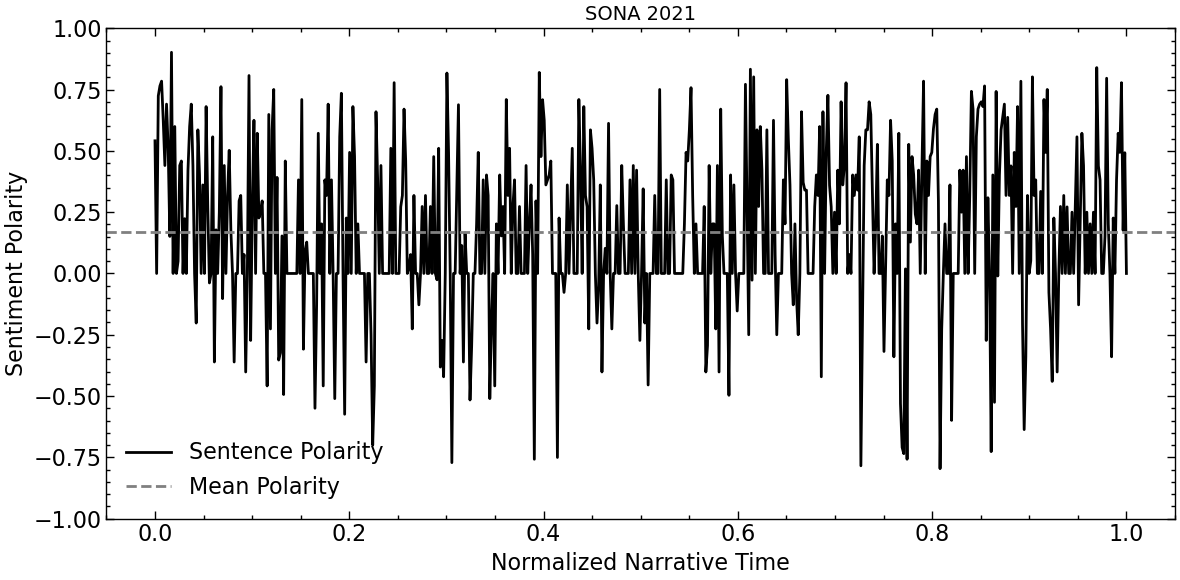

"25"
Number of sentences detected: 558
------------------------------
0.0 0.4389
0.0017953321364452424 0.7177
0.003590664272890485 0.5859
0.005385996409335727 0.0
0.00718132854578097 0.4767
0.008976660682226212 0.0
0.010771992818671455 0.296
0.012567324955116697 0.0
0.01436265709156194 -0.4854
0.01615798922800718 0.4019
0.017953321364452424 -0.1027
0.019748653500897665 -0.128
0.02154398563734291 0.8555
0.02333931777378815 0.4404
0.025134649910233394 -0.6249
0.026929982046678635 0.0
0.02872531418312388 -0.4019
0.03052064631956912 -0.1531
0.03231597845601436 0.25
0.03411131059245961 0.0
0.03590664272890485 -0.926
0.03770197486535009 0.5994
0.03949730700179533 -0.4215
0.04129263913824058 -0.5574
0.04308797127468582 0.2023
0.04488330341113106 0.8126
0.0466786355475763 0.2732
0.04847396768402154 0.0
0.05026929982046679 0.0
0.05206463195691203 0.4019
0.05385996409335727 0.0
0.05565529622980251 -0.34
0.05745062836624776 0.6124
0.059245960502693 0.3597
0.06104129263913824 0.3182
0.062836624775

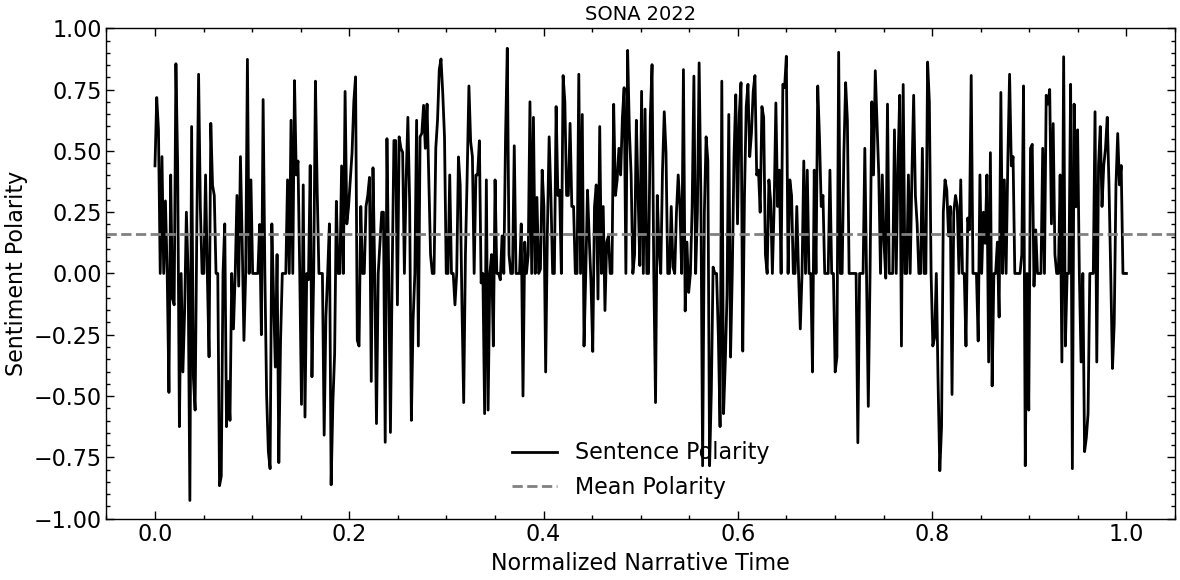

"26"
Number of sentences detected: 522
------------------------------
0.0 0.3182
0.0019193857965451055 0.0
0.003838771593090211 0.7177
0.005758157389635317 0.4389
0.007677543186180422 0.0
0.009596928982725527 0.4389
0.011516314779270634 0.5411
0.013435700575815739 0.0
0.015355086372360844 0.3182
0.01727447216890595 0.5267
0.019193857965451054 0.0
0.02111324376199616 0.0
0.023032629558541268 0.8225
0.02495201535508637 0.5423
0.026871401151631478 0.0
0.028790786948176585 0.798
0.030710172744721688 0.128
0.03262955854126679 0.0
0.0345489443378119 0.0
0.036468330134357005 -0.1531
0.03838771593090211 -0.2263
0.04030710172744722 -0.6808
0.04222648752399232 0.2732
0.044145873320537425 0.1531
0.046065259117082535 0.4019
0.04798464491362764 0.3818
0.04990403071017274 0.836
0.05182341650671785 0.4019
0.053742802303262956 0.0
0.05566218809980806 0.4404
0.05758157389635317 0.0
0.05950095969289827 0.1779
0.061420345489443376 0.3252
0.06333973128598848 -0.34
0.06525911708253358 -0.2263
0.06717850287

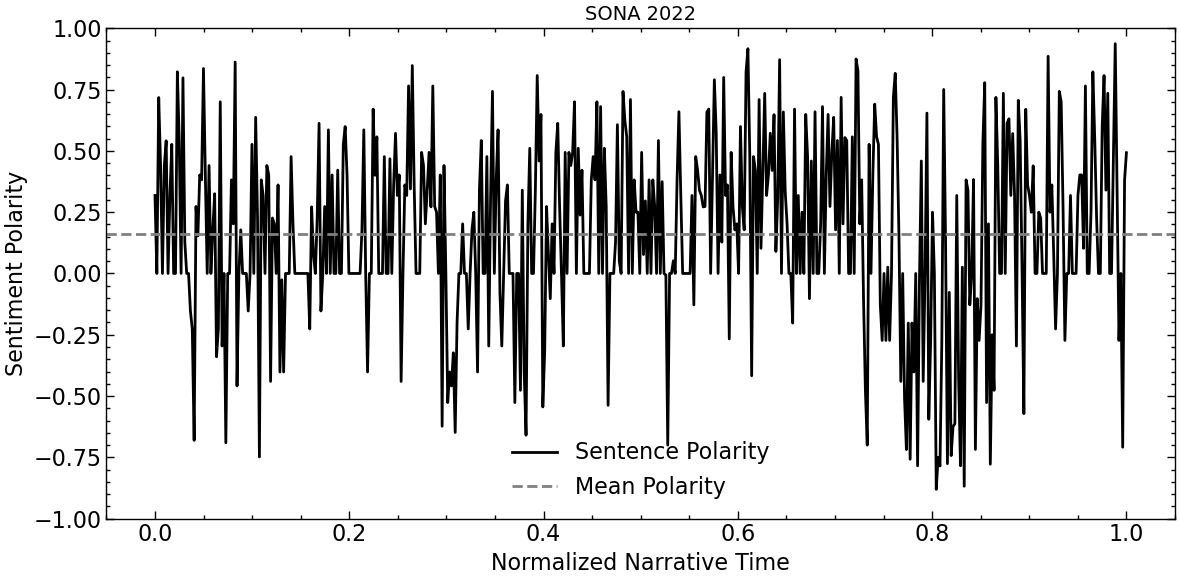

"27"
Number of sentences detected: 601
------------------------------
0.0 0.3818
0.0016666666666666668 0.9381
0.0033333333333333335 0.6249
0.005 0.8625
0.006666666666666667 0.0
0.008333333333333333 0.0
0.01 0.7184
0.011666666666666667 0.6705
0.013333333333333334 0.3818
0.015 0.3182
0.016666666666666666 0.0
0.018333333333333333 0.0
0.02 0.5994
0.021666666666666667 0.0
0.023333333333333334 0.5994
0.025 0.0
0.02666666666666667 0.2023
0.028333333333333332 0.7351
0.03 0.5106
0.03166666666666667 0.0
0.03333333333333333 0.128
0.035 0.0
0.03666666666666667 0.4404
0.03833333333333333 0.0
0.04 0.2732
0.041666666666666664 0.5423
0.043333333333333335 0.3612
0.045 0.5106
0.04666666666666667 0.7351
0.04833333333333333 0.2023
0.05 0.2023
0.051666666666666666 0.802
0.05333333333333334 0.3818
0.055 0.0
0.056666666666666664 0.5994
0.058333333333333334 0.5574
0.06 0.4939
0.06166666666666667 0.0
0.06333333333333334 0.0
0.065 0.0
0.06666666666666667 0.0
0.06833333333333333 0.3818
0.07 0.34
0.07166666666666

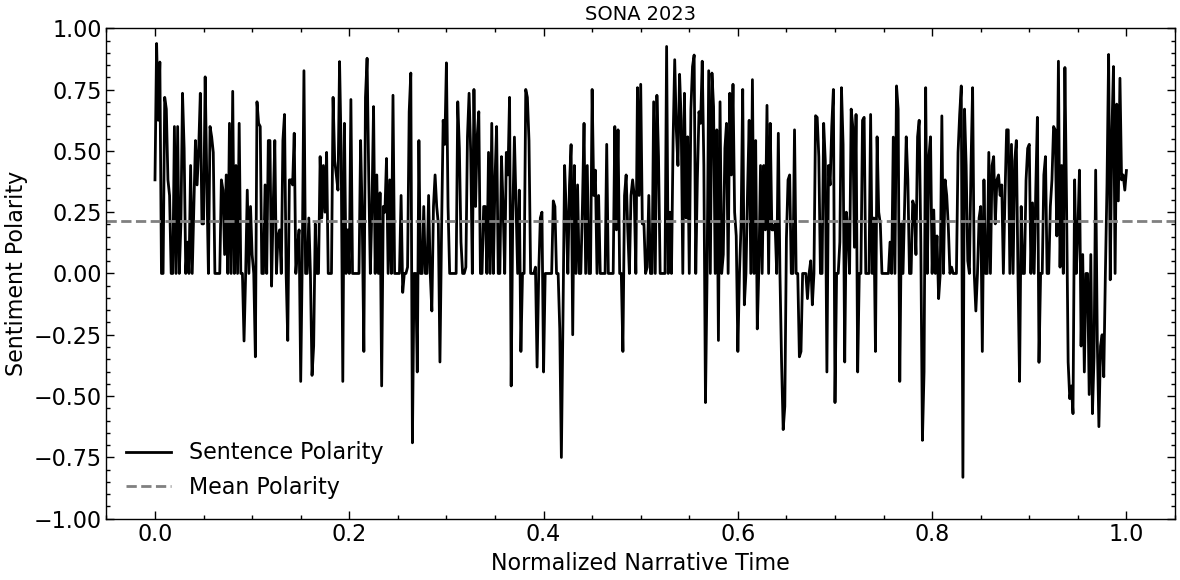

"28"
Number of sentences detected: 536
------------------------------
0.0 0.4389
0.001869158878504673 0.9273
0.003738317757009346 0.7906
0.005607476635514018 0.2732
0.007476635514018692 0.2023
0.009345794392523364 0.0
0.011214953271028037 -0.5859
0.013084112149532711 0.34
0.014953271028037384 -0.296
0.016822429906542057 0.2241
0.018691588785046728 0.4019
0.020560747663551402 0.4404
0.022429906542056073 0.0
0.024299065420560748 0.2023
0.026168224299065422 0.5106
0.028037383177570093 -0.3252
0.029906542056074768 0.0
0.03177570093457944 0.0
0.03364485981308411 0.4939
0.03551401869158879 0.2732
0.037383177570093455 0.3804
0.03925233644859813 0.0
0.041121495327102804 0.0
0.04299065420560748 -0.0772
0.044859813084112146 0.5719
0.04672897196261682 0.0
0.048598130841121495 0.0
0.05046728971962617 0.0
0.052336448598130844 0.3612
0.05420560747663551 0.4404
0.056074766355140186 0.7717
0.05794392523364486 0.3182
0.059813084112149535 0.3804
0.0616822429906542 0.7003
0.06355140186915888 0.0
0.065420

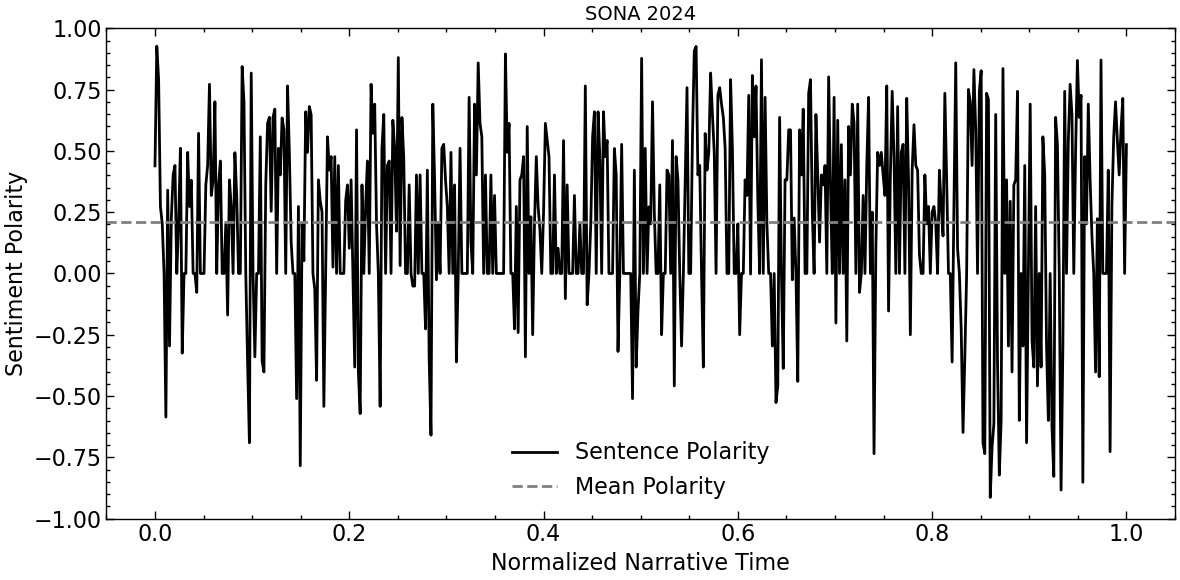

In [15]:
for index, row in data_sentiment.iterrows():
    text = row['Clean_Text']
    id = row['ID']
    year = row['Year']

    polarities, mean_polarity = create_sent_curve(text, id)

    if not polarities:
        continue  # Skip if no data

    # Split t and polarity values
    t_values, polarity_values = zip(*polarities)

    # Plot
    plt.figure(figsize=(12, 6))
    plt.plot(t_values, polarity_values, label='Sentence Polarity', color='black')
    plt.axhline(mean_polarity, color='gray', linestyle='--', label='Mean Polarity')

    plt.title(f"SONA {year}", fontsize=14)
    plt.xlabel("Normalized Narrative Time")
    plt.ylabel("Sentiment Polarity")
    plt.ylim(-1, 1)
    plt.legend()
    plt.grid(False)
    plt.tight_layout()
    plt.show()

"1"
Number of sentences detected: 795
------------------------------
0.0 0.836
0.0012594458438287153 0.7964
0.0025188916876574307 0.7579
0.003778337531486146 0.0772
0.005037783375314861 0.0
0.006297229219143577 -0.5719
0.007556675062972292 0.3818
0.008816120906801008 -0.1779
0.010075566750629723 -0.6705
0.011335012594458438 0.7878
0.012594458438287154 0.8225
0.013853904282115869 0.2732
0.015113350125944584 0.0772
0.0163727959697733 0.4019
0.017632241813602016 0.4767
0.018891687657430732 0.5423
0.020151133501259445 0.7003
0.021410579345088162 0.7003
0.022670025188916875 0.8658
0.02392947103274559 0.7579
0.02518891687657431 0.5423
0.02644836272040302 0.25
0.027707808564231738 0.0
0.028967254408060455 0.3612
0.030226700251889168 -0.4019
0.031486146095717885 -0.6517
0.0327455919395466 0.4215
0.03400503778337532 0.0
0.03526448362720403 0.0
0.036523929471032744 0.872
0.037783375314861464 0.8625
0.03904282115869018 0.5106
0.04030226700251889 0.8625
0.041561712846347604 0.0
0.04282115869017632

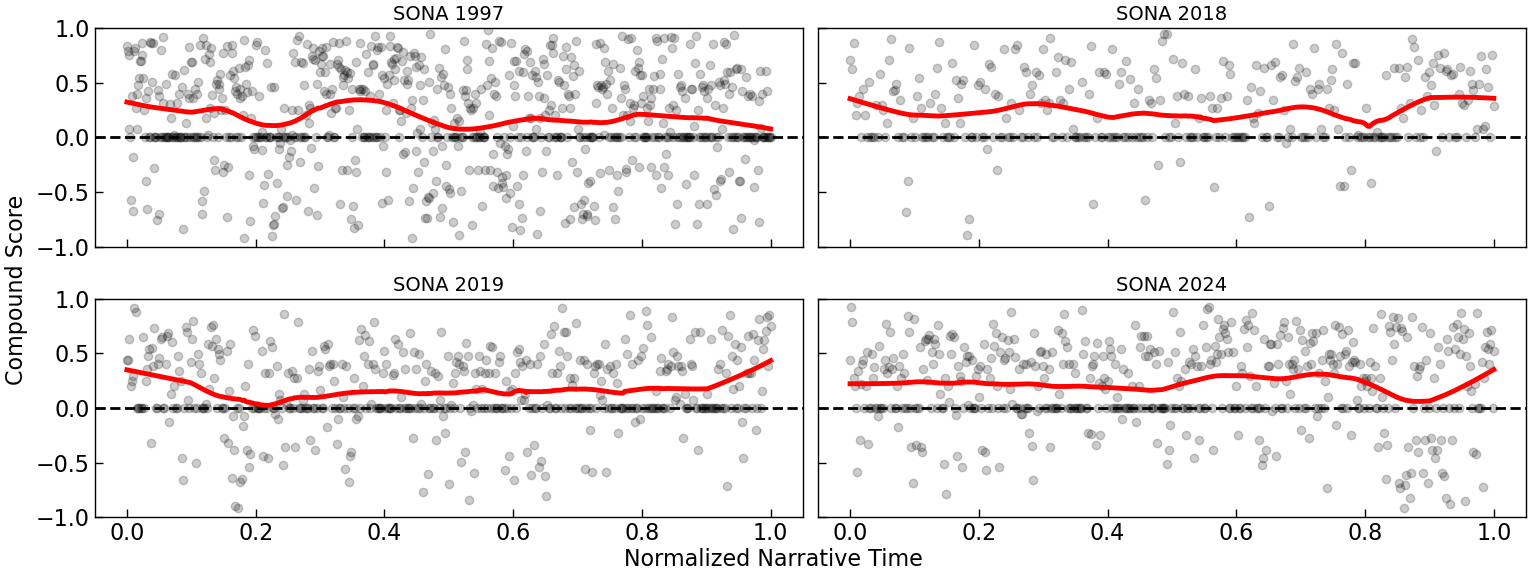

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(16, 6))
axes = axes.flatten()

ids_to_plot = [1, 21, 22, 28]

for idx, target_id in enumerate(ids_to_plot):
    id_data = data_sentiment[data_sentiment['ID'] == target_id]
    
    if id_data.empty:
        continue

    row = id_data.squeeze()

    text = row['Clean_Text']
    year = row['Year']

    polarities, mean_polarity = create_sent_curve(text, target_id)

    if not polarities:
        continue

    t_values, polarity_values = zip(*polarities)
    t_values = np.array(t_values)
    polarity_values = np.array(polarity_values)
    
    smooth_t, smooth_polarity, _ = loess_1d(
        x=t_values,
        y=polarity_values,
        degree=1,        
        frac=0.20
    )

    ax = axes[idx]
    ax.scatter(t_values, polarity_values, label='Sentence Polarity', c="black", alpha=0.2)
    ax.plot(smooth_t, smooth_polarity, label='Smoothed', color='red', linewidth=3.5)
    ax.axhline(0, color='black', linestyle='--', linewidth=2, zorder=0)
    
    ax.set_title(f"SONA {year}", fontsize=14)

    # hide individual x and y labels
    ax.set_xlabel("")
    ax.set_ylabel("")
    
    # only keep ticks where necessary
    if idx not in [2, 3]:
        ax.set_xticklabels([])
    if idx not in [0, 2]:
        ax.set_yticklabels([])

    ax.set_ylim(-1, 1)
    ax.set_yticks([-1, -0.5, 0, 0.5, 1])
    ax.grid(False)

    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')
    ax.minorticks_off()

# add central labels
fig.text(0.52, 0.04, 'Normalized Narrative Time', ha='center', fontsize=16)
fig.text(0.04, 0.5, 'Compound Score', va='center', rotation='vertical', fontsize=16)

plt.tight_layout(rect=[0.05, 0.05, 1, 1])  # leave space for labels
fig.savefig("vader.pdf", dpi=300, bbox_inches='tight')
plt.show()

In [17]:
roberta = pd.read_csv("roberta_output_v2.csv")
roberta

,doc_id,id,sentence,dspan,predict
0,1,1,"prosperity, security and ever growing welfare ...","(0, 137)",4.550781
1,1,2,"we are in for a new century, new times are com...","(138, 190)",3.888672
2,1,4,each epoch sets its own goals,"(198, 227)",2.765625
3,1,5,heine introduction,"(228, 246)",3.435547
4,1,6,"nothing is more remote as yesterday, nothing i...","(247, 319)",2.675781
...,...,...,...,...,...
12264,28,522,let us work together to make our homeland a ju...,"(56530, 56662)",5.332031
12265,28,523,we share a common high mission: to build a jus...,"(56663, 56786)",5.320312
12266,28,524,"as the head of state, i will make every effort...","(56787, 56935)",5.121094
12267,28,525,may our sacred homeland – kazakhstan – prosper!,"(56936, 56983)",5.234375


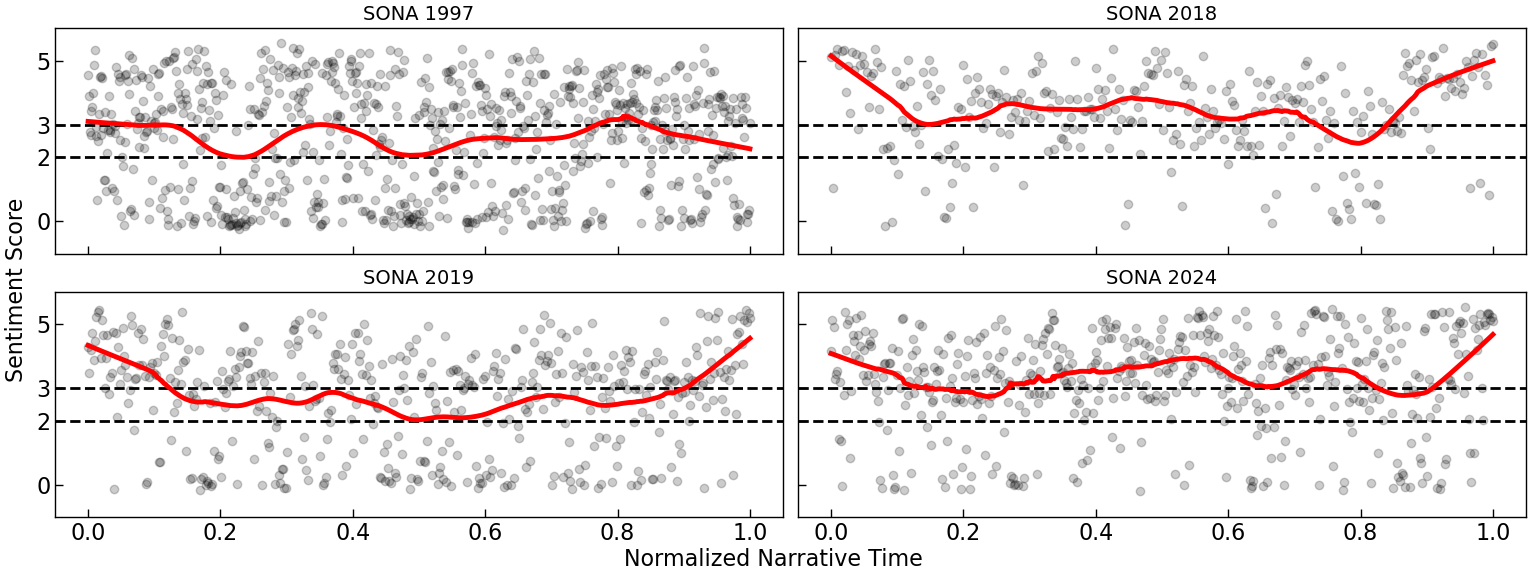

In [47]:
def create_sent_curve_from_doc(data, doc_id):
    doc_data = data[data['doc_id'] == doc_id].sort_values('id')
    
    if doc_data.empty:
        return [], None
    
    n = len(doc_data)
    t_values = np.linspace(0, 1, n)
    polarity_values = doc_data['predict'].values
    
    polarities = list(zip(t_values, polarity_values))
    mean_polarity = np.mean(polarity_values)
    
    return polarities, mean_polarity

# Main plotting section
fig, axes = plt.subplots(2, 2, figsize=(16, 6))
axes = axes.flatten()

docs_to_plot = [1, 21, 22, 28] 
doc_year_map = {
    1: 1997,
    21: 2018,
    22: 2019,
    28: 2024
}

for idx, doc_id in enumerate(docs_to_plot):
    polarities, mean_polarity = create_sent_curve_from_doc(roberta, doc_id)

    if not polarities:
        continue

    t_values, polarity_values = zip(*polarities)
    t_values = np.array(t_values)
    polarity_values = np.array(polarity_values)
    
    smooth_t, smooth_polarity, _ = loess_1d(
        x=t_values,
        y=polarity_values,
        degree=1,
        frac=0.20
    )

    ax = axes[idx]
    ax.scatter(t_values, polarity_values, label='Sentence Polarity', c="black", alpha=0.2)
    ax.plot(smooth_t, smooth_polarity, label='Smoothed', color='red', linewidth=3.5)
    ax.axhline(3, color='black', linestyle='--', linewidth=2, zorder=0)
    ax.axhline(2, color='black', linestyle='--', linewidth=2, zorder=0)

    year = doc_year_map[doc_id]
    ax.set_title(f"SONA {year}", fontsize=14)

    ax.set_xlabel("")
    ax.set_ylabel("")

    if idx not in [2, 3]:
        ax.set_xticklabels([])
    if idx not in [0, 2]:
        ax.set_yticklabels([])

    ax.set_ylim(-1, 6)  
    ax.set_yticks([0, 2, 3, 5])
    ax.grid(False)

    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')
    ax.minorticks_off()

fig.text(0.52, 0.04, 'Normalized Narrative Time', ha='center', fontsize=16)
fig.text(0.04, 0.5, 'Sentiment Score', va='center', rotation='vertical', fontsize=16)

plt.tight_layout(rect=[0.05, 0.05, 1, 1])
fig.savefig("roberta.pdf", dpi=300, bbox_inches='tight')
plt.show()

In [19]:
def get_3_category_label(x: float) -> str:
    x = max(0, min(x, 5))
    
    if x < 1.5:
        return 'Negative'
    elif x < 3.5:
        return 'Neutral'
    else:
        return 'Positive'
roberta["category"] = roberta["predict"].apply(get_3_category_label)
roberta

,doc_id,id,sentence,dspan,predict,category
0,1,1,"prosperity, security and ever growing welfare ...","(0, 137)",4.550781,Positive
1,1,2,"we are in for a new century, new times are com...","(138, 190)",3.888672,Positive
2,1,4,each epoch sets its own goals,"(198, 227)",2.765625,Neutral
3,1,5,heine introduction,"(228, 246)",3.435547,Neutral
4,1,6,"nothing is more remote as yesterday, nothing i...","(247, 319)",2.675781,Neutral
...,...,...,...,...,...,...
12264,28,522,let us work together to make our homeland a ju...,"(56530, 56662)",5.332031,Positive
12265,28,523,we share a common high mission: to build a jus...,"(56663, 56786)",5.320312,Positive
12266,28,524,"as the head of state, i will make every effort...","(56787, 56935)",5.121094,Positive
12267,28,525,may our sacred homeland – kazakhstan – prosper!,"(56936, 56983)",5.234375,Positive


In [37]:
mean_scores = roberta.groupby('doc_id')['predict'].mean().reset_index()
mean_scores.rename(columns={'predict': 'mean_predict'}, inplace=True)
mean_scores

,doc_id,mean_predict
0,1,2.595257
1,2,2.866428
2,3,1.800859
3,4,2.367051
4,5,2.693567
5,6,2.990131
6,7,3.324042
7,8,3.174088
8,9,3.469415
9,10,3.509658


In [ ]:
positive_share = (
    roberta.groupby("doc_id")["category"]
    .apply(lambda x: (x == "Positive").mean())
    .reset_index(name="positive_share")
)

In [48]:
negative_share = (
    roberta.groupby("doc_id")["category"]
    .apply(lambda x: (x == "Negative").mean())
    .reset_index(name="negative_share")
)

In [49]:
negative_share

,doc_id,negative_share
0,1,0.317500
1,2,0.269625
2,3,0.547826
3,4,0.331210
4,5,0.256318
5,6,0.196970
6,7,0.082251
7,8,0.108696
8,9,0.123543
9,10,0.089431


In [50]:
roberta_df = positive_share.merge(data_sentiment[['ID', 'Year']], left_on='doc_id', right_on='ID', how='left')
roberta_df = roberta_df.merge(negative_share[['doc_id', 'negative_share']], on='doc_id', how='left')
roberta_df = roberta_df.drop(columns=['ID'])
roberta_df

,doc_id,positive_share,Year,negative_share
0,1,0.371250,1997,0.317500
1,2,0.419795,1998,0.269625
2,3,0.208696,1999,0.547826
3,4,0.270701,2000,0.331210
4,5,0.310469,2001,0.256318
5,6,0.368687,2002,0.196970
6,7,0.437229,2003,0.082251
7,8,0.410628,2004,0.108696
8,9,0.538462,2005,0.123543
9,10,0.560976,2006,0.089431


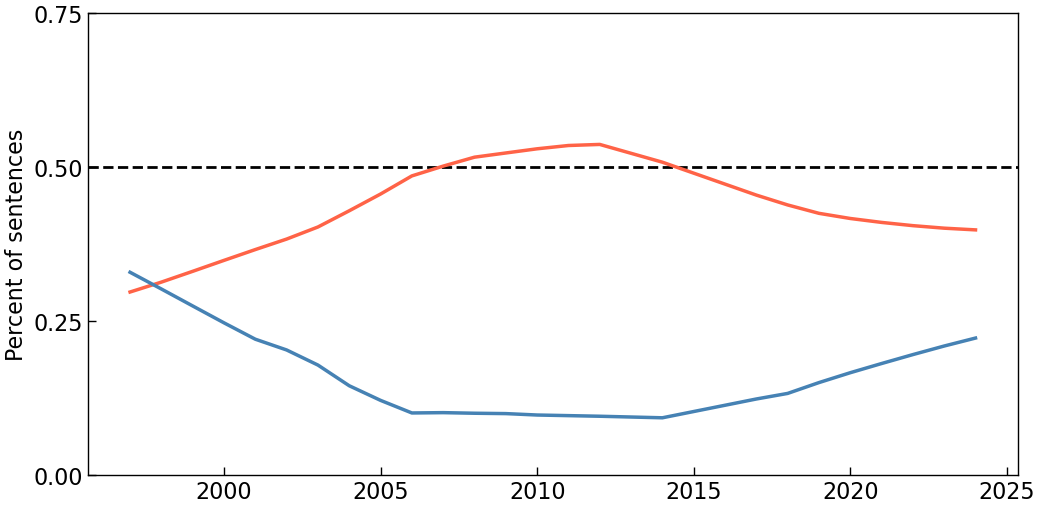

In [58]:
# Existing variables
x = roberta_df['Year'].values

# Positive share LOESS
y_pos = roberta_df['positive_share'].values
xout_pos, yout_pos, _ = loess_1d(x, y_pos, xnew=None, degree=1, frac=0.5)

# Negative share LOESS
y_neg = roberta_df['negative_share'].values
xout_neg, yout_neg, _ = loess_1d(x, y_neg, xnew=None, degree=1, frac=0.5)

# Plot
plt.figure(figsize=(12, 6))
plt.ylabel("Percent of sentences")

plt.plot(xout_pos, yout_pos, linewidth=2.5, color='tomato', label='Positive (LOESS)')
plt.plot(xout_neg, yout_neg, linewidth=2.5, color='steelblue', label='Negative (LOESS)')
plt.axhline(0.5, color='black', linestyle='--', linewidth=2, zorder=0)
plt.grid(False)
ax = plt.gca()
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
ax.minorticks_off()
plt.ylim(0, 0.65)
plt.yticks([0, 0.25, 0.50, 0.75])

plt.savefig("overall_sentiment.pdf", dpi=300, bbox_inches='tight')
plt.show()

In [24]:
#roberta_df.to_csv("roberta_df.csv", index=False)

In [35]:
shares = (
    roberta.groupby("doc_id")["category"]
    .agg(
        positive_share=lambda x: (x == "Positive").mean(),
        neutral_share=lambda x: (x == "Neutral").mean(),
        negative_share=lambda x: (x == "Negative").mean()
    )
    .reset_index()
)

roberta_df_all = shares.merge(data_sentiment[['ID', 'Year']], left_on='doc_id', right_on='ID', how='left')
roberta_df_all = roberta_df_all.drop(columns=['ID'])
roberta_df_all

,doc_id,positive_share,neutral_share,negative_share,Year
0,1,0.371250,0.311250,0.317500,1997
1,2,0.419795,0.310580,0.269625,1998
2,3,0.208696,0.243478,0.547826,1999
3,4,0.270701,0.398089,0.331210,2000
4,5,0.310469,0.433213,0.256318,2001
5,6,0.368687,0.434343,0.196970,2002
6,7,0.437229,0.480519,0.082251,2003
7,8,0.410628,0.480676,0.108696,2004
8,9,0.538462,0.337995,0.123543,2005
9,10,0.560976,0.349593,0.089431,2006


In [ ]:
#roberta_df_all.to_csv("roberta_df_all.csv", index=False)